# Lab01 - sprint 1

Узенбаев Арслан, Палыгина Евгения, Козельцева Полина, Серяга Евгений

## Данные

Источник: открытая база продуктов питания Open Food Facts (https://world.openfoodfacts.org/data, лицензия ODbL). В базе собраны сведения с этикеток продуктов, которые вносят пользователи из разных стран. Мы взяли полную выгрузку от 22.10.2026 и оставили из нее все продукты категории «йогурты» (`en:yogurts`), 37 453 записи. В файле `data/yogurts_off_raw.csv.gz` сохранены только нужные столбцы: штрихкод, название, бренд, страны, категории и пищевая ценность на 100 г.

Объект исследования: один йогурт (товарная позиция). Случайный эксперимент: из всех йогуртов, представленных на рынке и попавших в базу, наугад выбирается один, и с его этикетки считываются значения пищевой ценности. Все величины даны в граммах на 100 г продукта.

Генеральной совокупностью мы считаем все молочные йогурты базы с полностью заполненной пищевой ценностью. Перед анализом данные очищены:

- удалены повторяющиеся штрихкоды;
- оставлены записи, где указаны белки, жиры, углеводы, сахара и энергетическая ценность;
- исключены растительные йогурты (соевые, кокосовые и т.п.), так как это другой продукт с другим составом;
- удалены физически невозможные значения: белок больше 25 г, жиры больше 30 г, сахаров больше, чем углеводов, сумма белков, жиров и углеводов больше 100 г;
- удалены записи, где энергетическая ценность расходится с рассчитанной по составу (формула $4Б + 9Ж + 4У$, подробнее в разделе про белок) больше чем на 15%. Такое расхождение почти всегда означает ошибку при вводе этикетки.

Для анализа выбраны три величины: содержание белка, сахаров и жиров. Основное внимание уделено белку.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
import lab_utils as lu

lu.set_style()
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
raw = pd.read_csv('data/yogurts_off_raw.csv.gz', dtype={'code': str})
yog, steps = lu.clean_yogurts(raw)
display(steps)
print('страны с наибольшим числом йогуртов:')
print(yog['countries_tags'].fillna('').str.split(',').explode().value_counts().head(6))

,шаг,осталось записей
0,исходная выгрузка,37453
1,без повторов штрихкода,37452
2,"заполнены белки, жиры, углеводы, сахара, энергия",33565
3,без растительных йогуртов,33155
4,физически возможные значения,33008
5,энергия согласуется с составом (±15%),32151


страны с наибольшим числом йогуртов:
countries_tags
en:france           8508
en:united-states    5955
en:germany          3006
en:italy            2788
en:spain            2567
en:switzerland      1799
Name: count, dtype: int64


После очистки осталось $N = 32\,151$ йогурт. Больше всего продуктов из Франции и США. Российских йогуртов с полной пищевой ценностью всего 70: на российских этикетках часто не указывают содержание сахаров, поэтому большая часть российских записей не прошла второй шаг очистки.

In [ ]:
lu.describe_table({c: yog[c] for c in ['proteins_100g', 'sugars_100g', 'fat_100g']})

,proteins_100g,sugars_100g,fat_100g
n,3.215e+04,3.215e+04,3.215e+04
E,4.521,9.31,2.944
D,5.087,19.7,6.888
sigma,2.255,4.438,2.624
"CV, %",49.89,47.67,89.14
min,0,0,0
Q1,3.2,5,1
медиана,3.7,10,2.734
Q3,5,12.67,3.7
max,25,59.1,29.6


Все три величины имеют большой относительный разброс (коэффициент вариации от 48% до 89%), то есть йогурты сильно различаются по составу. У белка и жиров заметна правая асимметрия. У сахаров асимметрия почти нулевая, но, как будет показано ниже, распределение двугорбое.

<a id="rv01"></a>
## Random Variable 01 (белок)

<a id="rv01-desc"></a>
### Description

Содержание белка в йогурте определяется в первую очередь молоком: в коровьем молоке около 3.2–3.4 г белка на 100 г (казеин и сывороточные белки), и при сквашивании это количество почти не меняется. Дальше все зависит от технологии и рецептуры. Если после сквашивания отделить часть сыворотки (греческий йогурт, скир), белок концентрируется и может доходить до 8–10 г. Если добавить сухое молоко или молочный белок, содержание тоже растет. Если же добавить фруктовый наполнитель или сироп, белок, наоборот, разбавляется. Кроме того, значение на этикетке округляется, и производитель может указывать его с допуском.

Поэтому для случайно выбранного йогурта содержание белка заранее неизвестно: оно зависит от рецептуры, которой в данных нет. Покажем, что по остальным известным характеристикам его нельзя вычислить по формуле.

Для сравнения сначала рассмотрим величину, которая как раз вычисляется по формуле. Энергетическая ценность продукта рассчитывается по составу с помощью коэффициентов Этуотера: 1 г белка или углеводов дает около 4 ккал, 1 г жира около 9 ккал:

$$E_{ккал} \approx 4Б + 9Ж + 4У$$

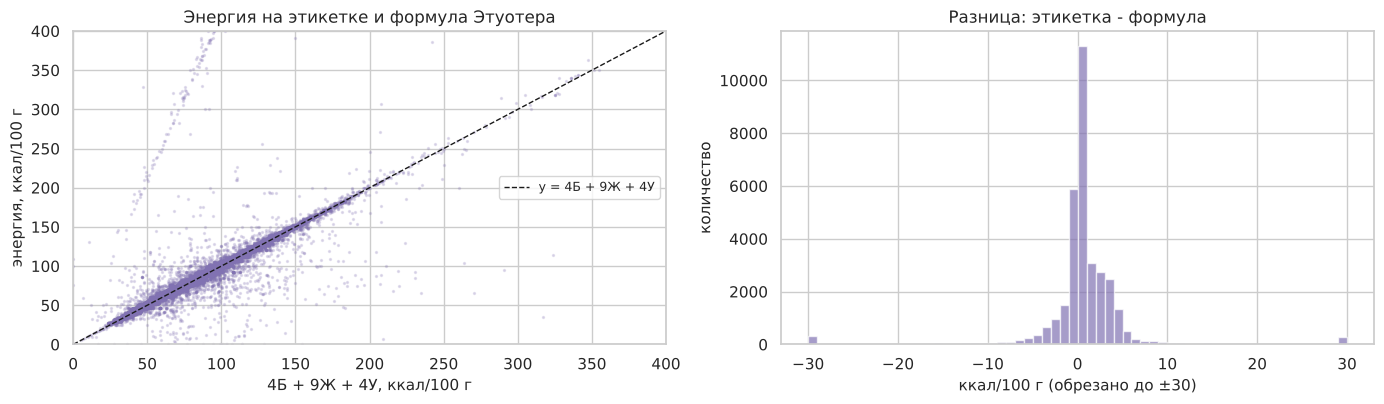

записей                     3.347e+04
медиана |разницы|, ккал           0.9
доля |разницы| <= 5 ккал        0.908
доля |разницы| <= 10 ккал       0.956
dtype: float64

In [ ]:
pd.Series(lu.atwater_check(raw)).round(3)

У 91% йогуртов (до очистки по этому признаку) значение на этикетке отличается от формулы не больше чем на 5 ккал, медианное расхождение 0.9 ккал. Это и есть детерминированная зависимость: энергия полностью определяется составом, остаток объясняется округлением. По этой причине энергию нельзя использовать для предсказания белка: она сама вычислена из белка.

Теперь попробуем предсказать белок по жирам, углеводам и сахарам. Используем случайный лес (модель, которая может уловить и нелинейные зависимости) с кросс-валидацией на 5 частях, чтобы оценка качества была честной. Если бы белок был функцией этих величин, коэффициент детерминации $R^2$ был бы близок к 1. Дополнительно для каждого йогурта найдем ближайшего «двойника» по жирам, углеводам и сахарам и сравним белок у них.

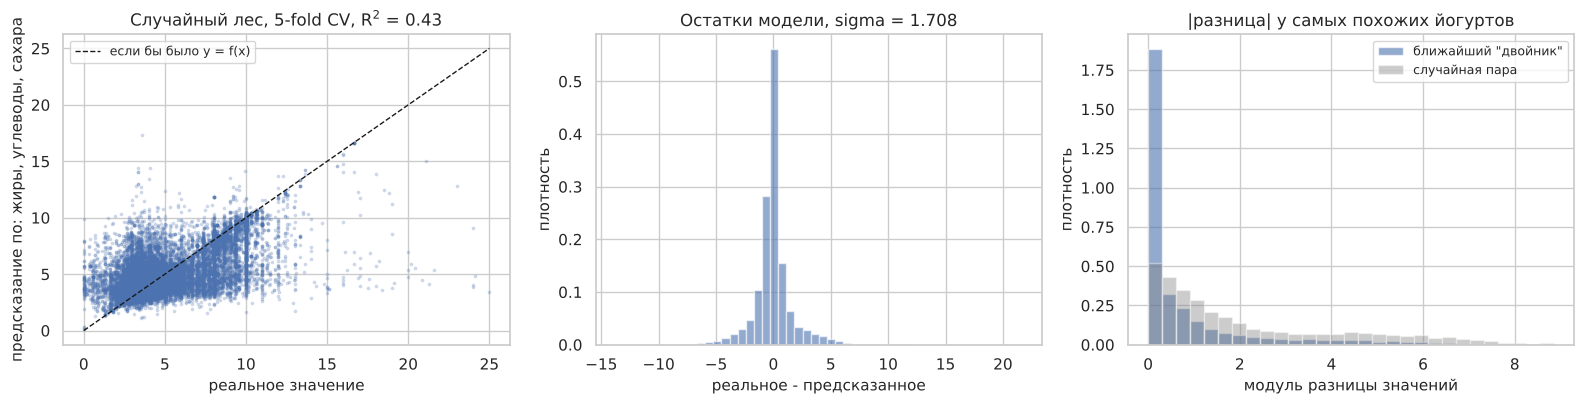

R2 (CV)                             0.426
sigma остатков                      1.708
sigma величины                      2.255
медиана |разн.| у двойников           0.2
медиана |разн.| у случайных пар      1.32
доля двойников с другим значением     0.6
dtype: float64

In [ ]:
features_p = ['fat_100g', 'carbohydrates_100g', 'sugars_100g']
rand_p = lu.randomness_check(yog, 'proteins_100g', features_p)
pd.Series(rand_p).round(3)

$R^2 = 0.43$: по остальным составляющим объясняется меньше половины разброса белка, остаточное стандартное отклонение 1.7 г при общем 2.3 г. Медианная разница белка у двойников 0.2 г против 1.3 г у случайной пары, то есть связь с составом есть, но она не детерминированная.

Еще нагляднее посмотреть на группы йогуртов с полностью совпадающими жирами, углеводами и сахарами:

In [ ]:
twins = lu.twins_exact(yog, 'proteins_100g', features_p)
print('групп из 5 и более йогуртов с одинаковыми жирами, углеводами и сахарами:', len(twins))
print('из них с разным белком:', (twins['размах'] > 0).mean().round(3))
twins.head(8).round(2)

групп из 5 и более йогуртов с одинаковыми жирами, углеводами и сахарами: 956
из них с разным белком: 0.748


,,,count,min,max,std,размах
fat_100g,carbohydrates_100g,sugars_100g,,,,,
10,4,4,94,2.8,9,1.33,6.2
3.7,13,12,77,3.1,3.5,0.05,0.4
0,4,4,75,2.9,11,1.54,8.1
3.2,14,13,67,3.1,3.8,0.1,0.7
3,12,12,63,0.16,4.6,0.58,4.44
10,3.5,3.5,62,2.7,8.3,1.24,5.6
1.18,14.71,10.59,60,2.94,3.53,0.08,0.59
3.1,13,12,57,2.8,4.9,0.48,2.1


В 75% таких групп белок различается. Например, у 94 йогуртов одинаково указаны 10 г жиров, 4 г углеводов и 4 г сахаров (это в основном жирные греческие йогурты), а белок у них от 2.8 до 9 г. Значит, содержание белка нельзя вычислить по другим показателям, и его следует рассматривать как случайную величину.

Также проверим, случаен ли порядок записей в файле: от этого зависит, как формировать выборку.

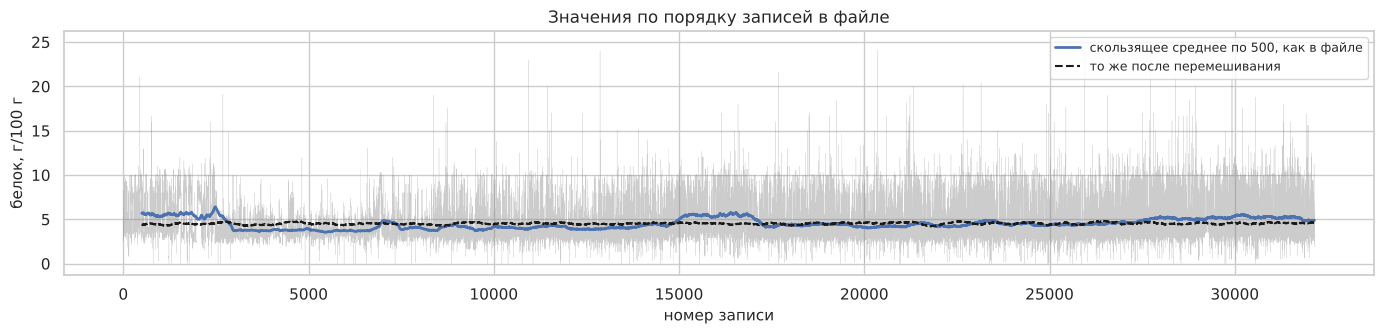

доля продуктов из США: в первых 1000 строках 0.925, во всей совокупности 0.185


критерий серий, z                    -30.41
критерий серий, p-value                   0
автокорреляция lag 1                 0.2236
автокорреляция после перемешивания   0.0021
dtype: float64

In [ ]:
order_p = lu.order_check(yog['proteins_100g'], 'proteins_100g')
print(f"доля продуктов из США: в первых 1000 строках {yog['usa'].iloc[:1000].mean():.3f}, во всей совокупности {yog['usa'].mean():.3f}")
pd.Series(order_p).round(4)

Критерий серий отвергает гипотезу о случайном порядке ($p \approx 10^{-203}$), автокорреляция соседних записей 0.22, а после перемешивания почти 0. Записи сгруппированы: в первых 1000 строках 92.5% американских продуктов при 18.5% во всей совокупности. Поэтому выборку нельзя брать как первые $n$ строк файла, ее нужно формировать случайно.

<a id="rv01-eda"></a>
### EDA & Distribution

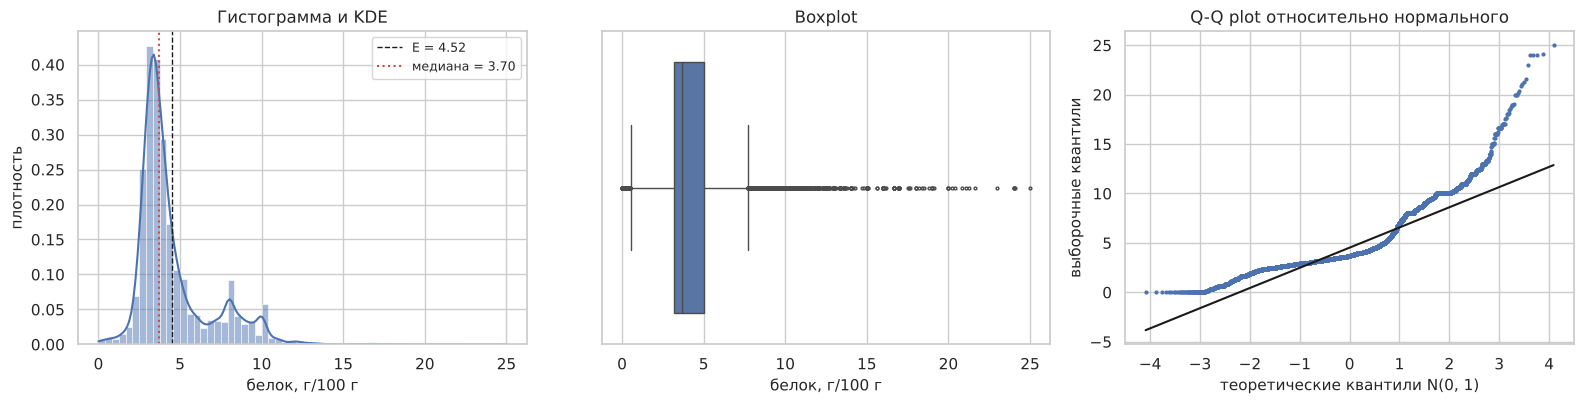

выбросов по правилу 1.5 IQR: 4441 (13.8%), границы [0.50, 7.70]
разных значений: 1791
самые частые значения: {3.5: 1364, 3.0: 1277, 3.3: 1273, 3.2: 1269, 4.0: 1222, 3.4: 1175}


In [ ]:
x = yog['proteins_100g']
lu.eda_plots(x, 'proteins_100g')
out, low, high = lu.outliers_iqr(x)
print(f'выбросов по правилу 1.5 IQR: {len(out)} ({len(out) / len(x) * 100:.1f}%), границы [{low:.2f}, {high:.2f}]')
print('разных значений:', x.nunique())
print('самые частые значения:', x.round(2).value_counts().head(6).to_dict())

Распределение явно несимметричное: среднее 4.52 г больше медианы 3.70 г, асимметрия 1.73. Основная масса йогуртов лежит в диапазоне 3–4 г, но справа есть длинный хвост и отдельный подъем около 8–10 г. По правилу 1.5 IQR выбросами оказываются 13.8% значений, почти все они справа. Однако это не ошибки, а отдельная группа продуктов, поэтому мы их не удаляем.

Видно также, что значения часто повторяются (3.5, 3.0, 3.3 и т.д.): производители округляют данные на этикетке до десятых. Предположим, что второй подъем дают греческие и высокобелковые йогурты, и проверим это.

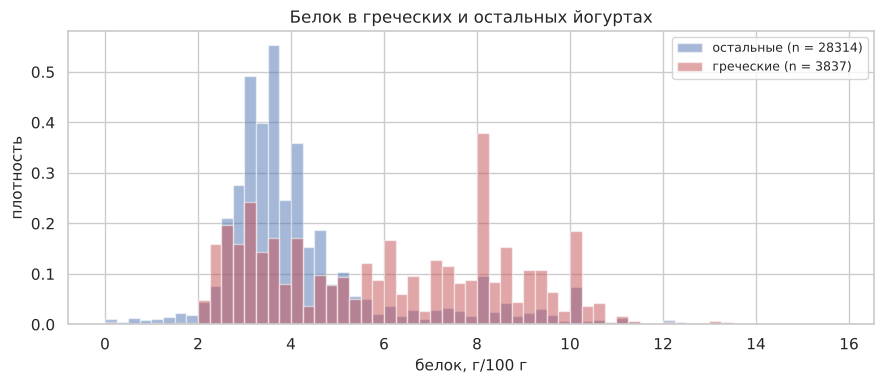

медиана белка: греческие 6.0 | остальные 3.6
доля йогуртов с белком от 6 г: 0.192


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 16, 0.25)
ax.hist(x[~yog['greek']], bins=bins, density=True, alpha=0.5, color=lu.COLORS['proteins_100g'], label=f"остальные (n = {(~yog['greek']).sum()})")
ax.hist(x[yog['greek']], bins=bins, density=True, alpha=0.5, color='#C44E52', label=f"греческие (n = {yog['greek'].sum()})")
ax.set_title('Белок в греческих и остальных йогуртах')
ax.set_xlabel(lu.LABELS['proteins_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()
print('медиана белка: греческие', x[yog['greek']].median(), '| остальные', x[~yog['greek']].median())
print('доля йогуртов с белком от 6 г:', round((x >= 6).mean(), 3))

Предположение подтверждается: у греческих йогуртов медиана 6.0 г против 3.6 г у остальных, и именно они формируют правый подъем. Около 19% всех йогуртов содержат 6 г белка и больше. Получается, что генеральная совокупность состоит из двух типов продуктов: обычных йогуртов и концентрированных (процеженных или обогащенных белком). Это нужно учитывать при выборе модели распределения.

Сравним несколько моделей. Параметры подбираются методом максимального правдоподобия, модели сравниваются по информационным критериям $AIC = 2k - 2\ln L$ и $BIC = k\ln n - 2\ln L$, где $k$ это число параметров, $L$ это значение функции правдоподобия. Чем меньше критерий, тем лучше модель; BIC сильнее штрафует за лишние параметры. Для логарифма нужны положительные значения, поэтому 58 йогуртов с нулевым белком исключены из подбора.

,число параметров,logL,AIC,BIC
нормальное,2,-7.155e+04,1.431e+05,1.431e+05
логнормальное,2,-6.506e+04,1.301e+05,1.301e+05
гамма,2,-6.58e+04,1.316e+05,1.316e+05
смесь 2 логнормальных,5,-6.35e+04,1.27e+05,1.271e+05


,компонента,вес w,mu,sigma,"медиана компоненты, г/100 г"
0,1,0.847,1.271,0.331,3.565
1,2,0.153,2.169,0.176,8.75


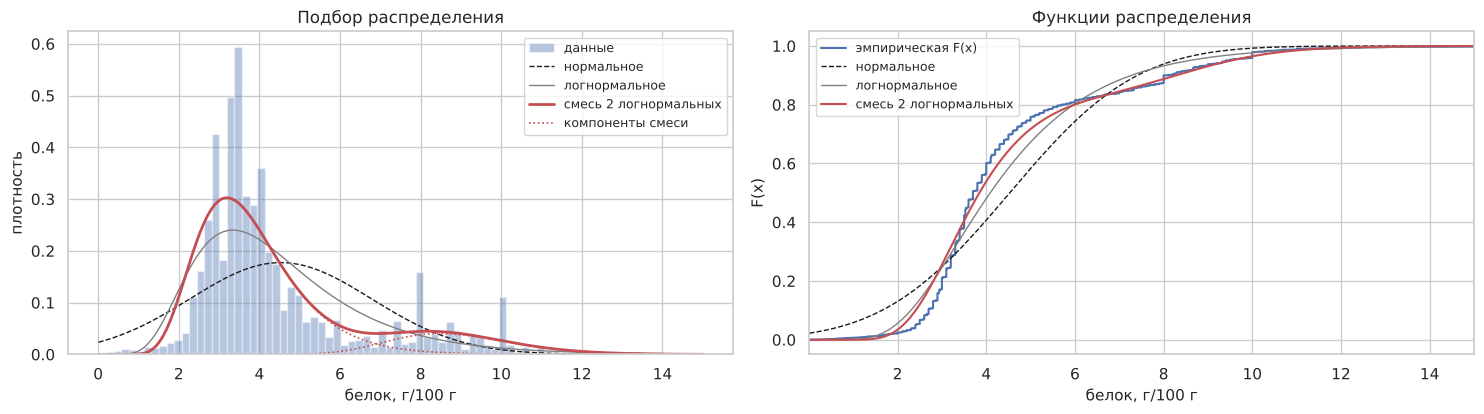

среднее по модели смеси: 4.548, среднее в данных: 4.529
удалено нулевых значений для логарифма: 58


In [ ]:
xp = x[x > 0]
mix_p = lu.fit_mixture(xp, k=2, log=True)
display(lu.fit_table(xp, mix_p))
display(lu.mixture_table(mix_p))
lu.plot_fits(xp, 'proteins_100g', mix_p, xmax=15)
e_mix = sum(w * np.exp(m + s ** 2 / 2) for w, m, s in zip(mix_p['w'], mix_p['mu'], mix_p['sd']))
print(f'среднее по модели смеси: {e_mix:.3f}, среднее в данных: {xp.mean():.3f}')
print(f"удалено нулевых значений для логарифма: {(x == 0).sum()}")

Из моделей с одной компонентой лучше всего подходит логнормальная, но она не может описать второй подъем. Смесь двух логнормальных распределений дает наименьшие AIC и BIC и хорошо повторяет эмпирическую функцию распределения. Первая компонента (85% йогуртов) имеет медиану 3.57 г, что соответствует обычному молоку, вторая (15%) имеет медиану 8.75 г, это концентрированные йогурты. Среднее по модели (4.55 г) почти совпадает со средним по данным (4.53 г).

<a id="rv01-math"></a>
#### Математическое описание распределения

Логнормальное распределение. Случайная величина $X > 0$ имеет логнормальное распределение, если ее логарифм распределен нормально: $\ln X \sim N(\mu, \sigma^2)$. Плотность:

$$f(x) = \frac{1}{x\sigma\sqrt{2\pi}} \exp\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right), \quad x > 0$$

Основные характеристики: медиана $e^{\mu}$, математическое ожидание $EX = e^{\mu + \sigma^2/2}$. Так как $EX > e^{\mu}$, распределение всегда скошено вправо. Оценки параметров по методу максимального правдоподобия: $\mu$ равно среднему значению $\ln x_i$, $\sigma$ равно стандартному отклонению $\ln x_i$.

Почему для белка естественно ожидать логнормальное распределение. Содержание белка получается как произведение нескольких факторов: исходный белок молока, коэффициент концентрирования (сколько сыворотки удалили), доля молочной основы в продукте (сколько добавили наполнителя). Логарифм произведения равен сумме логарифмов, а сумма многих независимых слагаемых по центральной предельной теореме близка к нормальной. Значит, логарифм белка примерно нормален, а сам белок логнормален.

Смесь распределений. Если совокупность состоит из нескольких групп, то плотность всей совокупности равна взвешенной сумме плотностей групп:

$$f(x) = w_1 f_1(x) + w_2 f_2(x), \quad w_1 + w_2 = 1$$

Такую модель удобно понимать как двухшаговый эксперимент: сначала с вероятностью $w_1$ выбирается обычный йогурт, а с вероятностью $w_2$ концентрированный, затем содержание белка берется из распределения соответствующей группы. Математическое ожидание смеси $EX = w_1 EX_1 + w_2 EX_2$. В нашей модели $f_1$ и $f_2$ логнормальные плотности. Параметры смеси нельзя выписать явной формулой, поэтому они находятся численно, EM-алгоритмом: на каждом шаге для каждого йогурта оценивается вероятность принадлежности к каждой группе, затем по этим вероятностям пересчитываются веса и параметры групп, и так до сходимости.

<a id="rv01-norm"></a>
#### Нормализация

Min-max нормализация $x' = \frac{x - \min}{\max - \min}$ переводит значения в отрезок $[0, 1]$ и не меняет форму распределения. Ее недостаток в чувствительности к крайним значениям: один йогурт с 25 г белка сжимает все остальные значения к началу отрезка.

Стандартизация $z = \frac{x - \mu}{\sigma}$ переводит величину в единицы стандартного отклонения: $z = 1.5$ означает, что значение на полторы сигмы больше среднего. После нее $E z = 0$ и $D z = 1$. Если исходная величина распределена нормально, то $z$ имеет стандартное нормальное распределение $N(0, 1)$: линейное преобразование нормальной величины тоже дает нормальную величину. Это удобно, потому что разные величины оказываются в одной шкале, их можно сравнивать между собой, а вероятности можно находить по одной таблице для $N(0, 1)$.

Так как белок ближе к логнормальному, сначала берем логарифм, а затем стандартизируем.

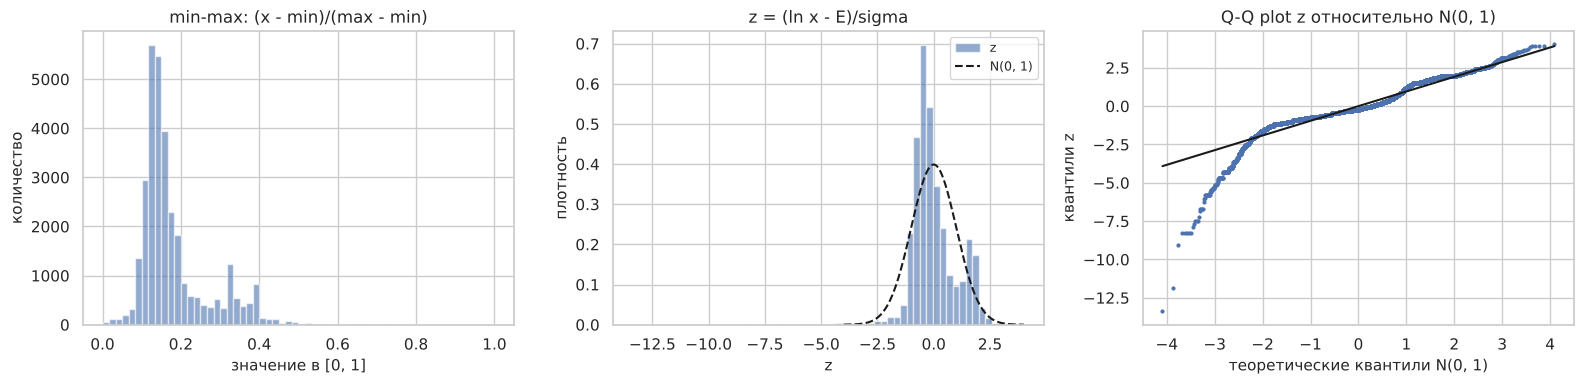

E(z) = 1.98e-16, sigma(z) = 1.0000
доля |z| < 1: 0.743 (у N(0, 1) 0.683)
доля |z| < 2: 0.964 (у N(0, 1) 0.954)
доля |z| < 3: 0.991 (у N(0, 1) 0.997)


In [ ]:
z_p = lu.normalize_plots(xp, 'proteins_100g', log=True)
print(f'E(z) = {z_p.mean():.2e}, sigma(z) = {z_p.std():.4f}')
for k, ref in [(1, 0.683), (2, 0.954), (3, 0.997)]:
    print(f'доля |z| < {k}: {np.mean(np.abs(z_p) < k):.3f} (у N(0, 1) {ref})')

После логарифмирования распределение стало заметно симметричнее, но до стандартного нормального не дотягивает: в интервал $|z| < 1$ попадает 74% значений вместо 68%, а за пределы $3\sigma$ выходит 0.9% вместо 0.3%. Острая вершина и тяжелые хвосты объясняются тем, что это смесь двух групп. Стандартизация, как и любое линейное преобразование, форму распределения не меняет.

<a id="rv01-est"></a>
### Independence & Estimations

Белок и жиры относятся к одной группе показателей (макронутриенты молочной основы). Проверим, зависимы ли они.

$H_0$: содержание белка и жиров независимы. Используем коэффициенты корреляции Пирсона (линейная связь) и Спирмена (монотонная связь), а также критерий хи-квадрат по таблице сопряженности групп. Силу связи по хи-квадрату оценим коэффициентом V Крамера (0 означает отсутствие связи, 1 полную связь). Уровень значимости здесь и далее $\alpha = 0.05$.

Пирсон: r = -0.202, p = 1.26e-294
Спирмен: rho = -0.200, p = 8.31e-288
хи-квадрат: chi2 = 7336, df = 9, p = 0, V Крамера = 0.276
на случайной выборке n = 1000: rho = -0.134, p = 2.26e-05


proteins_100g,до 3,3-4,4-6,больше 6
fat_100g,,,,
до 0.5,0.124,0.169,0.224,0.484
0.5-2,0.321,0.337,0.169,0.173
2-4,0.16,0.577,0.193,0.07
больше 4,0.277,0.319,0.288,0.116


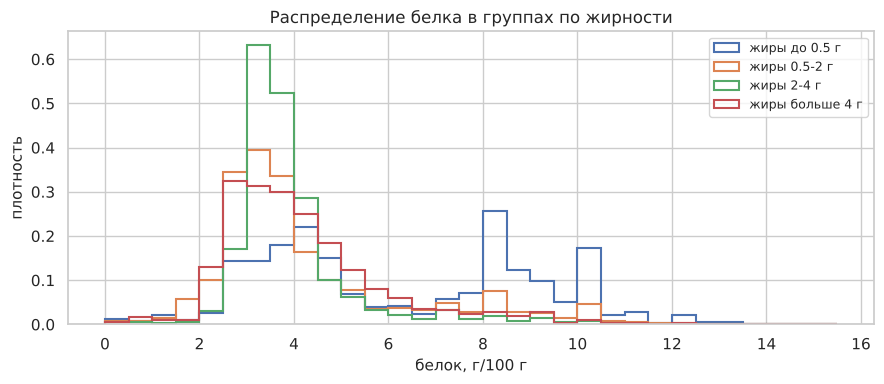

In [ ]:
p, f = yog['proteins_100g'], yog['fat_100g']
print(f'Пирсон: r = {stats.pearsonr(p, f).statistic:.3f}, p = {stats.pearsonr(p, f).pvalue:.3g}')
print(f'Спирмен: rho = {stats.spearmanr(p, f).statistic:.3f}, p = {stats.spearmanr(p, f).pvalue:.3g}')
fat_group = pd.cut(f, [-0.01, 0.5, 2, 4, 30], labels=['до 0.5', '0.5-2', '2-4', 'больше 4'])
prot_group = pd.cut(p, [-0.01, 3, 4, 6, 25], labels=['до 3', '3-4', '4-6', 'больше 6'])
table = pd.crosstab(fat_group, prot_group)
chi2, p_chi, dof, _ = stats.chi2_contingency(table)
print(f'хи-квадрат: chi2 = {chi2:.0f}, df = {dof}, p = {p_chi:.3g}, V Крамера = {np.sqrt(chi2 / (table.values.sum() * 3)):.3f}')
sample = yog.sample(1000, random_state=5)
print(f"на случайной выборке n = 1000: rho = {stats.spearmanr(sample['proteins_100g'], sample['fat_100g']).statistic:.3f}, p = {stats.spearmanr(sample['proteins_100g'], sample['fat_100g']).pvalue:.3g}")
display(pd.crosstab(fat_group, prot_group, normalize='index').round(3))
fig, ax = plt.subplots(figsize=(9, 4))
for g in fat_group.cat.categories:
    ax.hist(p[fat_group == g], bins=np.arange(0, 16, 0.5), density=True, histtype='step', lw=1.5, label=f'жиры {g} г')
ax.set_title('Распределение белка в группах по жирности')
ax.set_xlabel(lu.LABELS['proteins_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()

Гипотеза о независимости отвергается всеми тремя способами. Корреляция отрицательная, но слабая ($\rho = -0.20$), а по хи-квадрату связь умеренная (V = 0.28). Из таблицы видно, что связь немонотонная: среди обезжиренных йогуртов почти половина содержит больше 6 г белка, а среди йогуртов с жирностью 2–4 г таких только 7%. Это объясняется рынком: высокобелковые продукты (скир, греческие йогурты для спортивного питания) чаще всего делают обезжиренными. На случайной выборке из 1000 йогуртов вывод тот же ($\rho = -0.13$, $p = 2 \cdot 10^{-5}$).

Состоятельность оценок. Оценка $\hat\theta_n$ параметра $\theta$ называется состоятельной, если при росте объема выборки она сходится к истинному значению по вероятности:

$$P(|\hat\theta_n - \theta| > \varepsilon) \to 0, \quad n \to \infty \quad \text{для любого } \varepsilon > 0$$

Для выборочного среднего это следует из закона больших чисел, для выборочной дисперсии и медианы тоже.

Проверим это эмпирически. Генеральную совокупность считаем известной, из нее извлекаем выборки с возвращением объемом $n$ по 500 раз для каждого $n$ и считаем долю случаев, когда оценка отклонилась от значения в генеральной совокупности больше чем на $\varepsilon = 0.1\sigma$.

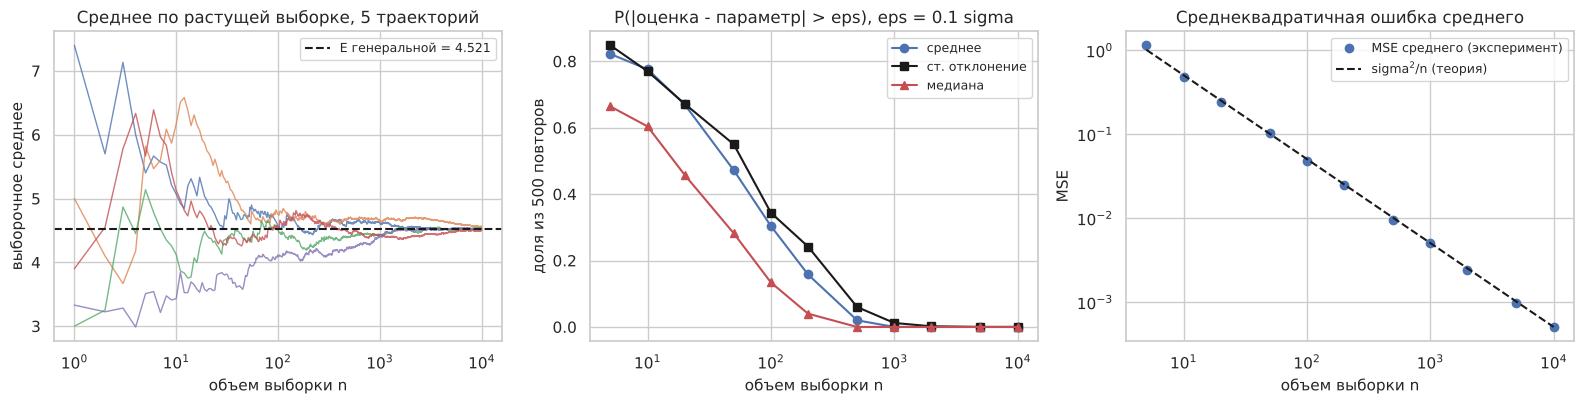

,n,P(|E* - E| > eps),P(|s - sigma| > eps),P(|Me* - Me| > eps),MSE(E*),sigma^2/n
0,5,0.822,0.848,0.664,1.149,1.017
1,10,0.776,0.77,0.604,0.4824,0.5087
2,20,0.67,0.672,0.458,0.2411,0.2544
3,50,0.472,0.55,0.282,0.1044,0.1017
4,100,0.304,0.344,0.134,0.04819,0.05087
5,200,0.158,0.242,0.04,0.02506,0.02544
6,500,0.02,0.06,0,0.00962,0.01017
7,1000,0,0.012,0,0.00513,0.00509
8,2000,0,0.002,0,0.00245,0.00254
9,5000,0,0,0,0.00098,0.00102


In [ ]:
cons_p = lu.consistency_plots(x, 'proteins_100g')
cons_p.round(5)

Для всех трех оценок (среднее, стандартное отклонение, медиана) доля больших ошибок падает с 66–85% при $n = 5$ практически до нуля при $n \ge 2000$, траектории выборочного среднего сходятся к 4.52. Значит, оценки состоятельные. Среднеквадратичная ошибка среднего совпадает с теоретической $\sigma^2/n$, то есть ошибка убывает как $1/\sqrt{n}$. Медиана здесь сходится быстрее среднего, потому что она находится в самом плотном месте распределения и не чувствительна к правому хвосту.

<a id="rv01-samp"></a>
### Sampling

Выборка с возвращением: каждый йогурт может попасть в выборку несколько раз, наблюдения независимы и одинаково распределены, поэтому дисперсия выборочного среднего равна $D\bar X = \frac{\sigma^2}{n}$.

Выборка без возвращения: каждый йогурт попадает не больше одного раза. Наблюдения становятся слабо зависимыми, и дисперсия среднего уменьшается:

$$D\bar X = \frac{\sigma^2}{n} \cdot \frac{N - n}{N - 1}$$

Множитель $\frac{N-n}{N-1}$ называется поправкой на конечность совокупности. При $n \ll N$ он близок к 1, а при $n = N$ равен 0: выборка совпадает с генеральной совокупностью.

Возьмем выборку объемом $n = 1000$ (около 3% совокупности) двумя способами и сравним с генеральной. Для сравнения добавим первые 1000 строк файла.

In [ ]:
table_p, s_with_p, s_without_p = lu.sample_compare(x)
table_p

,генеральная,с возвращением,без возвращения,первые 1000 строк
E,4.521,4.543,4.603,5.507
sigma,2.256,2.195,2.316,2.513
медиана,3.7,3.716,3.8,4.58
Q1,3.2,3.2,3.2,3.53
Q3,5,5.013,5,8
асимметрия,1.725,1.435,1.867,0.8033
эксцесс,4.091,2.26,6.168,0.9221
KS p-value (с генеральной),NaN,0.7967,0.7414,0
разных йогуртов в выборке,3.215e+04,989,1000,1000


Обе случайные выборки хорошо описывают генеральную совокупность: среднее 4.54 и 4.60 при 4.52, медиана и квартили отличаются не больше чем на 0.1 г, двухвыборочный критерий Колмогорова-Смирнова различий не находит (p = 0.80 и 0.74). Хуже всего оцениваются асимметрия и особенно эксцесс (2.3 и 6.2 при 4.1), так как они определяются редкими значениями в хвосте. В выборку с возвращением попало 989 разных йогуртов, остальное повторы.

Первые 1000 строк файла дают совсем другую картину: среднее 5.51, медиана 4.58, критерий Колмогорова-Смирнова отвергает совпадение распределений. Это следствие неслучайного порядка записей.

Проверим формулы для дисперсии среднего. Для каждого $n$ извлечем по 1000 выборок и посчитаем дисперсию полученных средних.

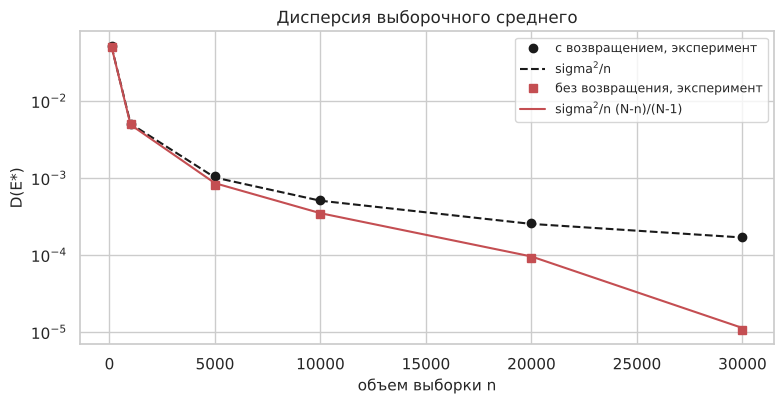

,n,n/N,"D(E*) с возвр., эксп.",sigma^2/n,"D(E*) без возвр., эксп.",sigma^2/n * (N-n)/(N-1)
0,100,0.00311,0.05263,0.05087,0.05068,0.05071
1,1000,0.0311,0.005041,0.005087,0.005069,0.004929
2,5000,0.1555,0.001053,0.001017,0.0008174,0.0008592
3,10000,0.311,0.0005172,0.0005087,0.0003472,0.0003505
4,20000,0.6221,0.0002631,0.0002544,9.155e-05,9.613e-05
5,30000,0.9331,0.0001705,0.0001696,1.062e-05,1.135e-05


In [ ]:
lu.fpc_experiment(x)

Экспериментальные значения совпадают с теоретическими. При малых $n$ способы почти не отличаются, а при $n = 20\,000$ (62% совокупности) дисперсия среднего без возвращения меньше в 2.9 раза, при $n = 30\,000$ в 16 раз. Вывод: если выборка составляет заметную долю генеральной совокупности, выборка без возвращения дает более точную оценку; при $n \ll N$ разницы между способами практически нет.

<a id="rv01-hyp"></a>
### Hypothesis

H1. $H_0$: содержание белка имеет логнормальное распределение (с одной компонентой). Проверка по выборке без возвращения $n = 1000$ критерием Шапиро-Уилка для $\ln X$, затем сравнение одно- и двухкомпонентной модели по BIC.

In [ ]:
for name, s in [('выборка без возвращения, n = 1000', s_without_p[s_without_p > 0]), ('генеральная совокупность', xp)]:
    print(name)
    print(f'   белок, Шапиро-Уилк: p = {stats.shapiro(s).pvalue:.3g}')
    print(f'   ln(белок), Шапиро-Уилк: p = {stats.shapiro(np.log(s)).pvalue:.3g}')
print()
print('сравнение моделей на выборке n = 1000 по BIC:')
sp = s_without_p[s_without_p > 0]
one = lu.fit_mixture(sp, k=1, log=True)
two = lu.fit_mixture(sp, k=2, log=True)
for m in [one, two]:
    k = 3 * m['k'] - 1
    print(f"   {m['name']}: BIC = {k * np.log(len(sp)) - 2 * m['logL']:.1f}")
print(f"веса смеси по выборке: {two['w'].round(3)}, медианы компонент: {np.exp(two['mu']).round(2)}")

выборка без возвращения, n = 1000
   белок, Шапиро-Уилк: p = 6.65e-33
   ln(белок), Шапиро-Уилк: p = 3.23e-22
генеральная совокупность
   белок, Шапиро-Уилк: p = 4.06e-102
   ln(белок), Шапиро-Уилк: p = 3.91e-83

сравнение моделей на выборке n = 1000 по BIC:
   смесь 1 логнормальных: BIC = 4071.4
   смесь 2 логнормальных: BIC = 3955.2
веса смеси по выборке: [0.819 0.181], медианы компонент: [3.55 8.6 ]


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 32093.
  res = hypotest_fun_out(*samples, **kwds)


Гипотеза отвергается: $p \approx 3 \cdot 10^{-22}$ уже на выборке, на генеральной совокупности тем более. Двухкомпонентная смесь по выборке дает меньший BIC, а ее параметры (веса 0.82 и 0.18, медианы 3.55 и 8.6 г) близки к параметрам по всей совокупности. То есть по выборке из 1000 йогуртов можно правильно восстановить структуру генеральной совокупности. Предупреждение scipy о точности p-value относится к расчету на всех 32 тысячах значений и на вывод не влияет.

H2. $H_0$: распределение белка в российских йогуртах такое же, как в остальных. Российских йогуртов всего 70, распределение далеко от нормального, поэтому основным выбран непараметрический критерий Манна-Уитни. Критерий Уэлча приведен для сравнения.

Россия: n = 70, медиана 3.30, среднее 4.27
остальные: n = 32081, медиана 3.70, среднее 4.52
доля греческих: Россия 0.114, остальные 0.119
Манн-Уитни: U = 983970, p = 0.0733
Уэлч: t = -1.11, p = 0.269
только не греческие: медиана Россия 3.25, остальные 3.60, Манн-Уитни p = 0.00894


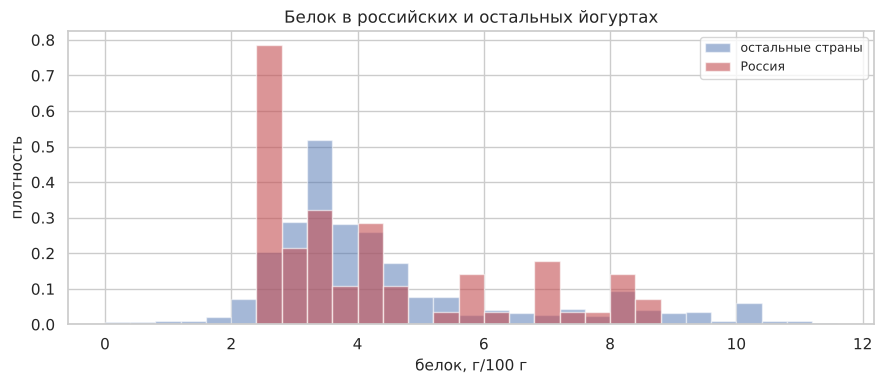

In [ ]:
ru = yog.loc[yog['russia'], 'proteins_100g']
other = yog.loc[~yog['russia'], 'proteins_100g']
u = stats.mannwhitneyu(ru, other, alternative='two-sided')
t = stats.ttest_ind(ru, other, equal_var=False)
print(f'Россия: n = {len(ru)}, медиана {ru.median():.2f}, среднее {ru.mean():.2f}')
print(f'остальные: n = {len(other)}, медиана {other.median():.2f}, среднее {other.mean():.2f}')
print(f'доля греческих: Россия {yog.loc[yog["russia"], "greek"].mean():.3f}, остальные {yog.loc[~yog["russia"], "greek"].mean():.3f}')
print(f'Манн-Уитни: U = {u.statistic:.0f}, p = {u.pvalue:.3g}')
print(f'Уэлч: t = {t.statistic:.2f}, p = {t.pvalue:.3g}')
reg = yog[~yog['greek']]
u2 = stats.mannwhitneyu(reg.loc[reg['russia'], 'proteins_100g'], reg.loc[~reg['russia'], 'proteins_100g'])
print(f"только не греческие: медиана Россия {reg.loc[reg['russia'], 'proteins_100g'].median():.2f}, остальные {reg.loc[~reg['russia'], 'proteins_100g'].median():.2f}, Манн-Уитни p = {u2.pvalue:.3g}")
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 12, 0.4)
ax.hist(other, bins=bins, density=True, alpha=0.5, color=lu.COLORS['proteins_100g'], label='остальные страны')
ax.hist(ru, bins=bins, density=True, alpha=0.6, color='#C44E52', label='Россия')
ax.set_title('Белок в российских и остальных йогуртах')
ax.set_xlabel(lu.LABELS['proteins_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()

По всем йогуртам гипотеза не отвергается: $p = 0.073 > 0.05$, хотя медиана в России ниже (3.3 г против 3.7 г). Доля греческих йогуртов в обеих группах одинаковая (около 12%). Если же сравнить только обычные йогурты, без греческих, то различие становится значимым: медиана 3.25 г против 3.60 г, $p = 0.009$. Значит, обычные российские йогурты в среднем содержат немного меньше белка, но на всей выборке эффект маскируется высокобелковыми продуктами. Этот вывод предварительный: 70 продуктов могут быть не вполне представительны для российского рынка.

<a id="rv01-res"></a>
### Resume

Содержание белка является случайной величиной: по жирам, углеводам и сахарам оно предсказывается только на 43%, а у йогуртов с одинаковыми остальными показателями различается. Распределение описывается смесью двух логнормальных: обычные йогурты (85%, медиана 3.6 г) и концентрированные (15%, медиана 8.8 г). Белок отрицательно связан с жирами, так как высокобелковые йогурты обычно обезжиренные. Оценки среднего, стандартного отклонения и медианы состоятельны, случайная выборка объемом 1000 хорошо описывает генеральную совокупность.

<a id="rv02"></a>
## Random Variable 02 (сахара)

<a id="rv02-desc"></a>
### Description

Сахара в йогурте складываются из двух частей. Первая часть есть в любом йогурте: это лактоза, молочный сахар. В молоке ее около 4.7 г на 100 г, при сквашивании молочнокислые бактерии перерабатывают часть лактозы в молочную кислоту, поэтому в готовом йогурте ее остается меньше. Вторая часть добавляется производителем: сахар, сироп, фруктовый наполнитель. Сколько сахара добавить, решает производитель, и это зависит от вкуса продукта, страны и маркетинга. Поэтому содержание сахаров у случайно выбранного йогурта тоже заранее неизвестно.

Сахара входят в состав углеводов, поэтому здесь связь с другими показателями ожидается сильнее, чем у белка. Проверим, насколько точно сахара можно восстановить по белку, жирам и углеводам.

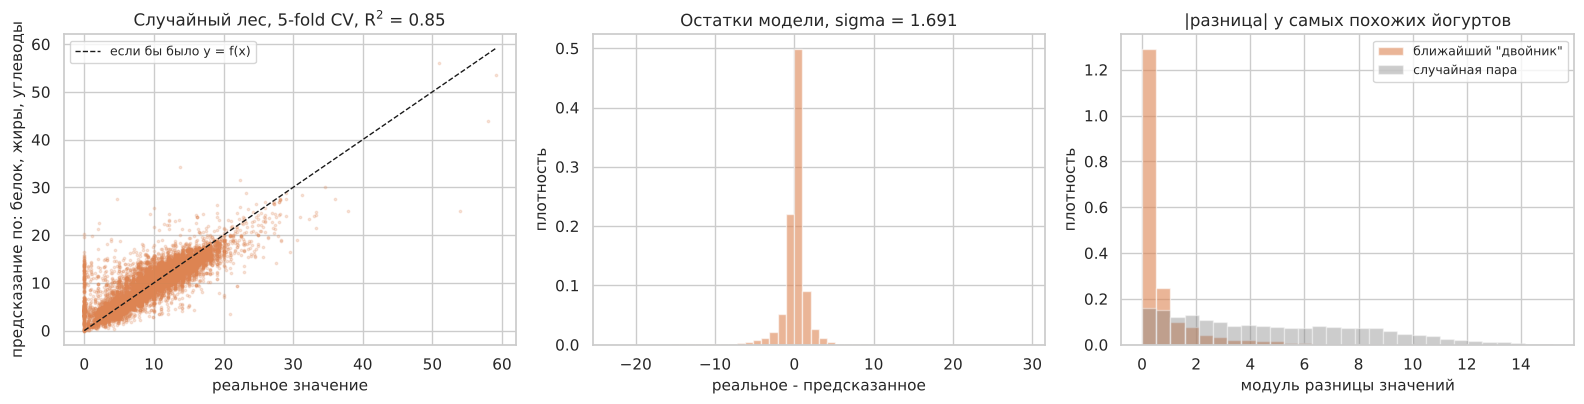

R2 (CV)                             0.855
sigma остатков                      1.691
sigma величины                      4.438
медиана |разн.| у двойников          0.04
медиана |разн.| у случайных пар      4.33
доля двойников с другим значением   0.525
dtype: float64

In [ ]:
features_s = ['proteins_100g', 'fat_100g', 'carbohydrates_100g']
rand_s = lu.randomness_check(yog, 'sugars_100g', features_s)
pd.Series(rand_s).round(3)

$R^2 = 0.86$: сахара предсказываются намного лучше, чем белок, что ожидаемо, ведь они являются частью углеводов. Однако зависимость не точная: остаточное стандартное отклонение 1.7 г, а у ближайших двойников сахара различаются в 53% случаев. Разница между углеводами и сахарами зависит от того, сколько в йогурте крахмала, загустителей, злаков и пищевых волокон, а этого в формуле нет. Поэтому сахара тоже следует считать случайной величиной, хотя и сильно связанной с углеводами.

<a id="rv02-eda"></a>
### EDA & Distribution

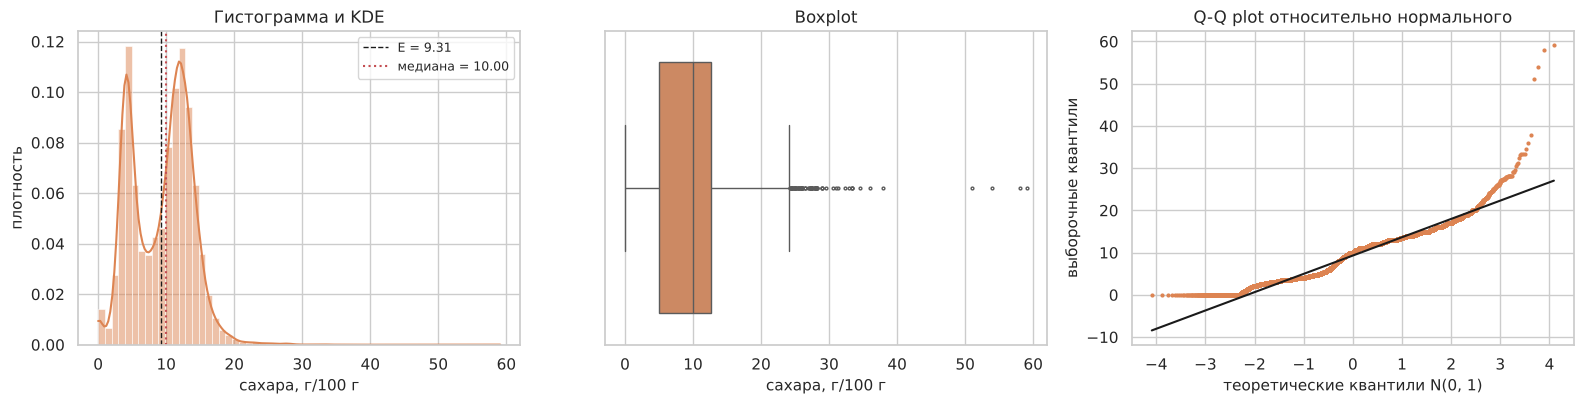

выбросов по правилу 1.5 IQR: 82 (0.3%), границы [-6.50, 24.17]
разных значений: 2381


In [ ]:
x = yog['sugars_100g']
lu.eda_plots(x, 'sugars_100g')
out, low, high = lu.outliers_iqr(x)
print(f'выбросов по правилу 1.5 IQR: {len(out)} ({len(out) / len(x) * 100:.1f}%), границы [{low:.2f}, {high:.2f}]')
print('разных значений:', x.nunique())

Асимметрия близка к нулю (0.25), среднее 9.3 г и медиана 10 г близки, выбросов по IQR всего 0.3%. При этом на гистограмме видны два отдельных пика: около 4–5 г и около 11–13 г, а Q-Q plot имеет S-образную форму. Естественное объяснение: первый пик дают йогурты без добавленного сахара, второй сладкие. Проверим это на категориях.

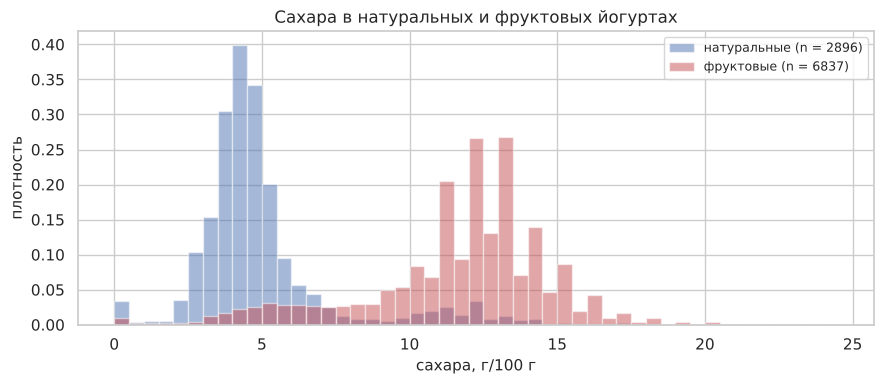

медиана сахаров: натуральные 4.4 | фруктовые 12.0


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 25, 0.5)
ax.hist(x[yog['plain']], bins=bins, density=True, alpha=0.5, color='#4C72B0', label=f"натуральные (n = {yog['plain'].sum()})")
ax.hist(x[yog['fruit']], bins=bins, density=True, alpha=0.5, color='#C44E52', label=f"фруктовые (n = {yog['fruit'].sum()})")
ax.set_title('Сахара в натуральных и фруктовых йогуртах')
ax.set_xlabel(lu.LABELS['sugars_100g'])
ax.set_ylabel('плотность')
ax.legend()
plt.tight_layout()
plt.show()
print('медиана сахаров: натуральные', x[yog['plain']].median(), '| фруктовые', x[yog['fruit']].median())

У натуральных йогуртов медиана сахаров 4.4 г, у фруктовых 12 г, и пики на гистограмме совпадают с этими группами. Значит, совокупность снова является смесью двух групп. Так как оба пика примерно симметричны, в качестве компонент возьмем нормальные распределения. Нулевые значения (335 йогуртов, 1%) исключены из подбора, так как лактоза присутствует в любом молочном йогурте, и ноль скорее означает безлактозный продукт или ошибку.

нулевых значений: 335, для подбора распределений они исключены


,число параметров,logL,AIC,BIC
нормальное,2,-9.197e+04,1.839e+05,1.84e+05
логнормальное,2,-9.65e+04,1.93e+05,1.93e+05
гамма,2,-9.242e+04,1.848e+05,1.849e+05
смесь 2 нормальных,5,-8.788e+04,1.758e+05,1.758e+05


,компонента,вес w,mu,sigma,"медиана компоненты, г/100 г"
0,1,0.314,4.245,1.201,4.245
1,2,0.686,11.77,3.034,11.77


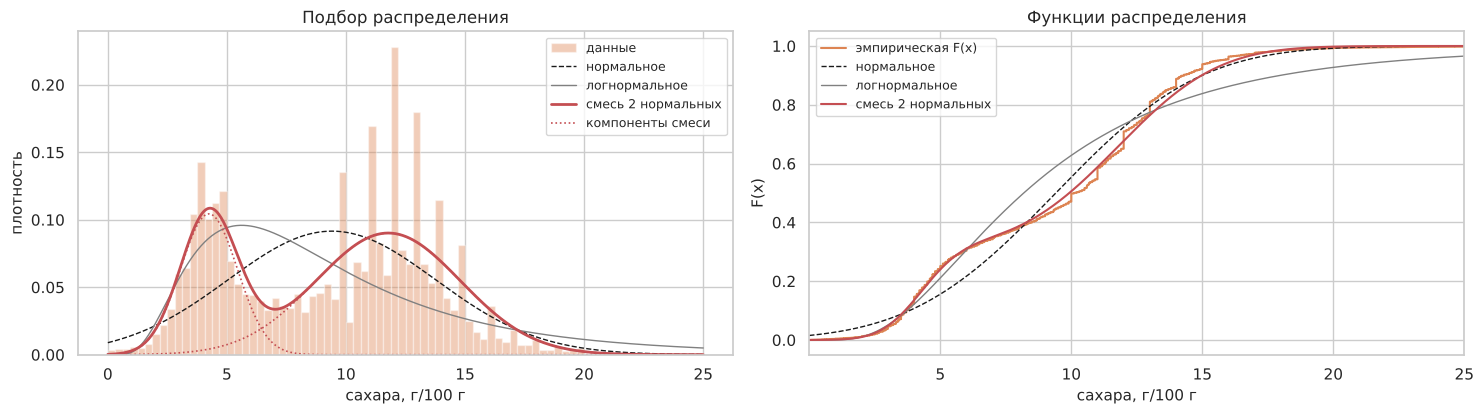

In [ ]:
xs = x[x > 0]
print(f'нулевых значений: {(x == 0).sum()}, для подбора распределений они исключены')
mix_s = lu.fit_mixture(xs, k=2, log=False)
display(lu.fit_table(xs, mix_s))
display(lu.mixture_table(mix_s))
lu.plot_fits(xs, 'sugars_100g', mix_s, xmax=25)

Смесь двух нормальных распределений значительно лучше любой однокомпонентной модели по AIC и BIC. Первая компонента (31%): среднее 4.2 г, $\sigma = 1.2$ г, это йогурты, где сахара представлены в основном лактозой. Вторая компонента (69%): среднее 11.8 г, $\sigma = 3.0$ г, это сладкие йогурты. Разность средних, около 7.5 г, примерно равна количеству добавленного сахара в типичном сладком йогурте. Логнормальное распределение здесь подходит хуже всех, так как распределение не скошено вправо.

Нормальное распределение $N(\mu, \sigma^2)$ имеет плотность

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right), \quad EX = \mu, \quad DX = \sigma^2$$

Оно симметрично относительно $\mu$, в интервал $\mu \pm \sigma$ попадает 68.3% значений, в $\mu \pm 2\sigma$ 95.4%, в $\mu \pm 3\sigma$ 99.7%. Смесь двух нормальных записывается так же, как в разделе про белок: $f(x) = w_1 f_1(x) + w_2 f_2(x)$, где $f_1$ и $f_2$ нормальные плотности.

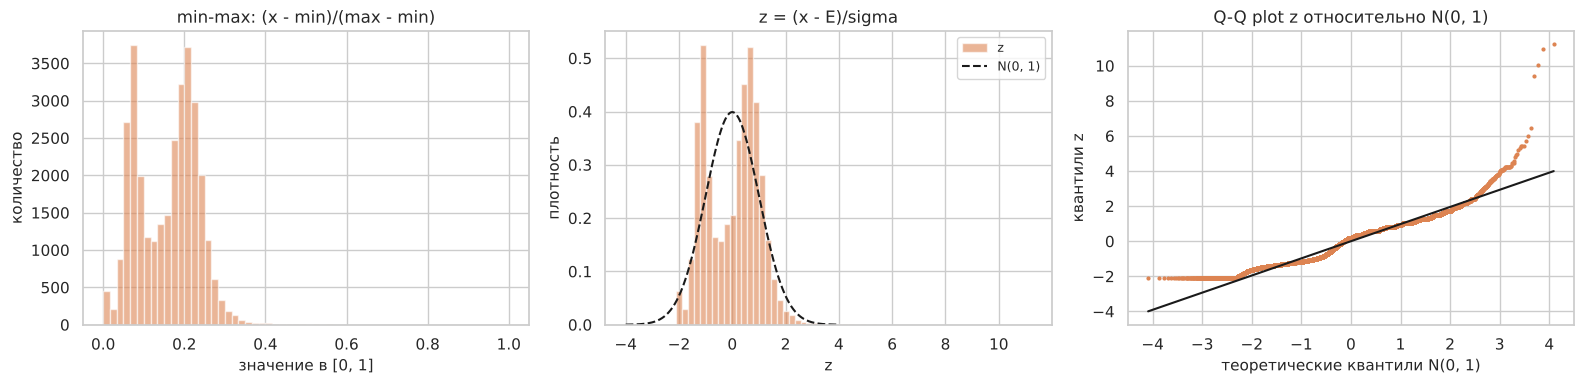

доля |z| < 1: 0.613 (у N(0, 1) 0.683)
доля |z| < 2: 0.975 (у N(0, 1) 0.954)
доля |z| < 3: 0.996 (у N(0, 1) 0.997)


In [ ]:
z_s = lu.normalize_plots(x, 'sugars_100g', log=False)
for k, ref in [(1, 0.683), (2, 0.954), (3, 0.997)]:
    print(f'доля |z| < {k}: {np.mean(np.abs(z_s) < k):.3f} (у N(0, 1) {ref})')

Стандартизация переводит сахара в шкалу $N(0, 1)$ по среднему и дисперсии, но форма остается двугорбой: в интервал $|z| < 1$ попадает только 61% значений вместо 68%, потому что значительная часть йогуртов находится между пиками и на них. Этот пример показывает, что стандартизация не делает распределение нормальным, она только меняет сдвиг и масштаб.

<a id="rv02-ind"></a>
### Independence & Estimations

Сахара и углеводы величины одной природы: сахара являются частью углеводов. $H_0$: сахара и углеводы независимы.

Пирсон: r = 0.915, p = 0
Спирмен: rho = 0.917, p = 0
доля сахаров в углеводах: медиана 0.933, Q1 0.842, Q3 1.000
йогуртов, где сахара = углеводы: 0.294
Спирмен для белка и сахаров: rho = -0.319


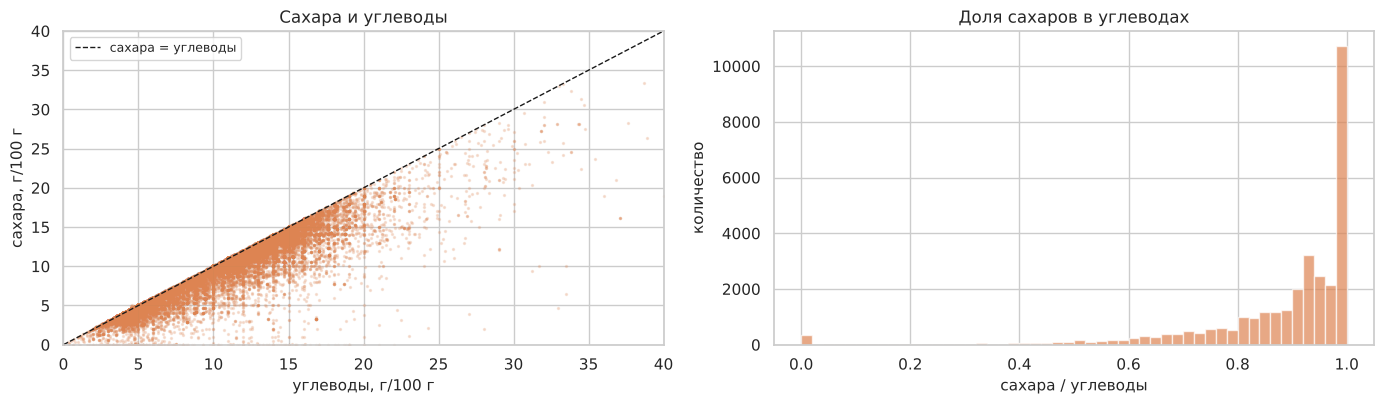

In [ ]:
s, c = yog['sugars_100g'], yog['carbohydrates_100g']
print(f'Пирсон: r = {stats.pearsonr(s, c).statistic:.3f}, p = {stats.pearsonr(s, c).pvalue:.3g}')
print(f'Спирмен: rho = {stats.spearmanr(s, c).statistic:.3f}, p = {stats.spearmanr(s, c).pvalue:.3g}')
share = s / c.where(c > 0)
print(f'доля сахаров в углеводах: медиана {share.median():.3f}, Q1 {share.quantile(0.25):.3f}, Q3 {share.quantile(0.75):.3f}')
print(f'йогуртов, где сахара = углеводы: {(s == c).mean():.3f}')
print(f"Спирмен для белка и сахаров: rho = {stats.spearmanr(yog['proteins_100g'], s).statistic:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].scatter(c, s, s=2, alpha=0.2, color=lu.COLORS['sugars_100g'])
axes[0].plot([0, 40], [0, 40], 'k--', lw=1, label='сахара = углеводы')
axes[0].set_xlim(0, 40)
axes[0].set_ylim(0, 40)
axes[0].set_title('Сахара и углеводы')
axes[0].set_xlabel(lu.LABELS['carbohydrates_100g'])
axes[0].set_ylabel(lu.LABELS['sugars_100g'])
axes[0].legend()
axes[1].hist(share.dropna().clip(0, 1), bins=50, color=lu.COLORS['sugars_100g'], alpha=0.7)
axes[1].set_title('Доля сахаров в углеводах')
axes[1].set_xlabel('сахара / углеводы')
axes[1].set_ylabel('количество')
plt.tight_layout()
plt.show()

Гипотеза о независимости отвергается: $\rho = 0.92$, $p$ практически равно нулю. Зависимость сильная, но не функциональная: в типичном йогурте (по медиане) сахара составляют 93% углеводов, у 29% йогуртов сахара равны углеводам, а у четверти доля меньше 84% (в таких йогуртах есть крахмал, злаки или загустители). Также отметим отрицательную связь сахаров с белком ($\rho = -0.32$): высокобелковые йогурты реже бывают сладкими.

Состоятельность оценок проверяется так же, как для белка.

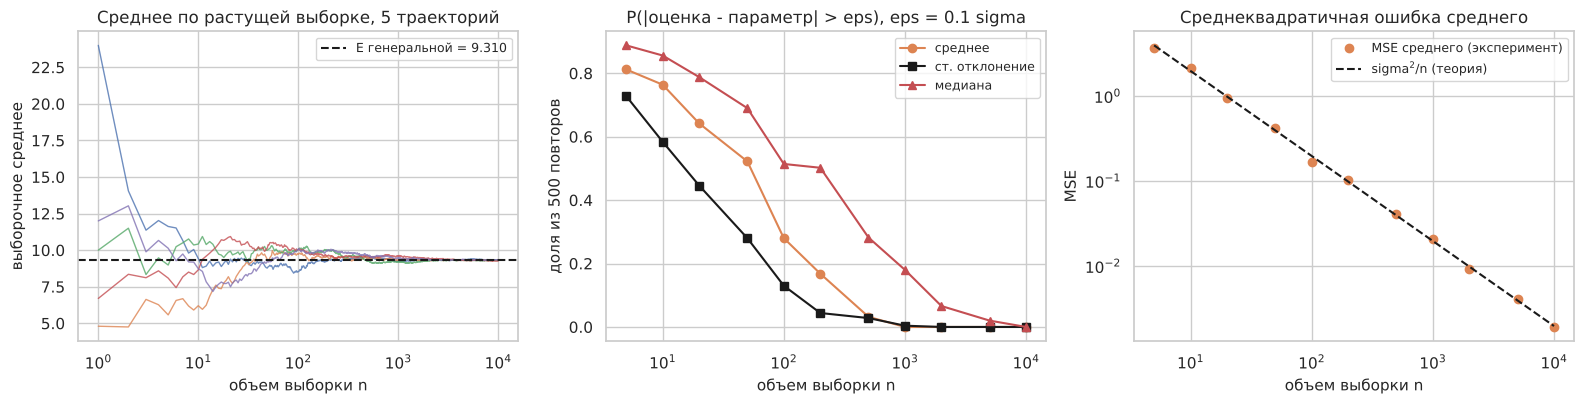

,n,P(|E* - E| > eps),P(|s - sigma| > eps),P(|Me* - Me| > eps),MSE(E*),sigma^2/n
0,5,0.812,0.728,0.888,3.689,3.94
1,10,0.764,0.584,0.856,2.12,1.97
2,20,0.642,0.446,0.788,0.9595,0.9849
3,50,0.522,0.28,0.69,0.4188,0.394
4,100,0.28,0.13,0.514,0.1664,0.197
5,200,0.168,0.044,0.502,0.1033,0.09849
6,500,0.032,0.028,0.282,0.04056,0.0394
7,1000,0,0.004,0.18,0.02068,0.0197
8,2000,0,0,0.066,0.00925,0.00985
9,5000,0,0,0.02,0.00411,0.00394


In [ ]:
cons_s = lu.consistency_plots(x, 'sugars_100g')
cons_s.round(5)

Среднее и стандартное отклонение сходятся так же, как для белка, MSE среднего совпадает с $\sigma^2/n$. Медиана сходится заметно медленнее: при $n = 1000$ она ошибается больше чем на $0.1\sigma$ в 18% случаев, и только к $n = 10\,000$ ошибки исчезают. Причина в форме распределения: медиана (10 г) находится в провале между двумя пиками, где значений мало, поэтому небольшое случайное изменение состава выборки сильно сдвигает медиану. Тем не менее доля ошибок стремится к нулю, и оценка остается состоятельной.

<a id="rv02-samp"></a>
### Sampling

In [ ]:
table_s, s_with_s, s_without_s = lu.sample_compare(x)
table_s

,генеральная,с возвращением,без возвращения,первые 1000 строк
E,9.31,9.372,9.607,10.4
sigma,4.438,4.381,4.448,5.059
медиана,10,10.15,10.69,10.59
Q1,5,5,5.1,6
Q3,12.67,12.7,13,13.53
асимметрия,0.2464,0.0149,0.0897,0.5686
эксцесс,1.22,-0.686,0.163,0.4737
KS p-value (с генеральной),NaN,0.8317,0.0505,0
разных йогуртов в выборке,3.215e+04,989,1000,1000


Выборка с возвращением хорошо совпадает с генеральной (KS p = 0.83). Выборке без возвращения в этот раз досталось чуть больше сладких йогуртов: среднее 9.61 при 9.31, это около двух стандартных ошибок, и критерий Колмогорова-Смирнова находится на границе значимости (p = 0.05). Такое отклонение возможно при случайном отборе и показывает, что одна выборка всегда несет случайную ошибку. Первые 1000 строк файла снова сильно отличаются от генеральной совокупности.

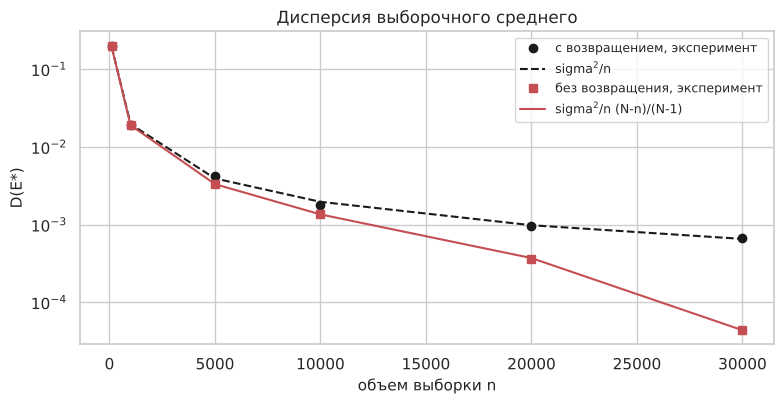

,n,n/N,"D(E*) с возвр., эксп.",sigma^2/n,"D(E*) без возвр., эксп.",sigma^2/n * (N-n)/(N-1)
0,100,0.00311,0.2021,0.197,0.199,0.1964
1,1000,0.0311,0.01936,0.0197,0.01922,0.01909
2,5000,0.1555,0.004235,0.00394,0.003388,0.003327
3,10000,0.311,0.001818,0.00197,0.001375,0.001357
4,20000,0.6221,0.000964,0.0009849,0.0003655,0.0003722
5,30000,0.9331,0.0006753,0.0006566,4.436e-05,4.393e-05


In [ ]:
lu.fpc_experiment(x)

Формулы для дисперсии среднего выполняются и для сахаров, поправка $\frac{N-n}{N-1}$ работает независимо от формы распределения.

<a id="rv02-hyp"></a>
### Hypothesis

H3. $H_0$: содержание сахаров имеет нормальное распределение (одна компонента). Проверка по выборке $n = 1000$.

In [ ]:
print('Шапиро-Уилк на выборке n = 1000:', f'p = {stats.shapiro(s_without_s).pvalue:.3g}')
one = lu.fit_mixture(s_without_s, k=1, log=False)
two = lu.fit_mixture(s_without_s, k=2, log=False)
for m in [one, two]:
    k = 3 * m['k'] - 1
    print(f"   {m['name']}: BIC = {k * np.log(len(s_without_s)) - 2 * m['logL']:.1f}")
print(f"веса смеси по выборке: {two['w'].round(3)}, центры компонент: {two['mu'].round(2)}")

Шапиро-Уилк на выборке n = 1000: p = 1.52e-17
   смесь 1 нормальных: BIC = 5835.6
   смесь 2 нормальных: BIC = 5638.0
веса смеси по выборке: [0.317 0.683], центры компонент: [ 4.22 12.11]


Гипотеза отвергается ($p \approx 10^{-17}$). Смесь двух нормальных по BIC лучше, а параметры, оцененные по выборке (веса 0.32 и 0.68, центры 4.2 и 12.1 г), почти совпадают с параметрами по всей совокупности.

H4. $H_0$: медиана содержания сахаров в натуральных йогуртах равна 4.7 г, то есть содержанию лактозы в исходном молоке. Если бактерии при сквашивании перерабатывают часть лактозы, то медиана должна быть меньше. Используем критерий знаковых рангов Уилкоксона.

In [ ]:
plain = x[yog['plain']]
w = stats.wilcoxon(plain - 4.7)
print(f'натуральные йогурты: n = {len(plain)}, медиана {plain.median():.2f}, среднее {plain.mean():.2f}')
print(f'Уилкоксон, H0: медиана = 4.7: p = {w.pvalue:.3g}')
print(f'доля натуральных йогуртов с сахарами меньше 4.7 г: {(plain < 4.7).mean():.3f}')
print(f'доля натуральных йогуртов с сахарами больше 8 г: {(plain > 8).mean():.3f}')

натуральные йогурты: n = 2896, медиана 4.40, среднее 4.92
Уилкоксон, H0: медиана = 4.7: p = 1.36e-18
доля натуральных йогуртов с сахарами меньше 4.7 г: 0.597
доля натуральных йогуртов с сахарами больше 8 г: 0.089


Гипотеза отвергается ($p \approx 10^{-18}$): медиана 4.4 г, у 60% натуральных йогуртов сахаров меньше, чем лактозы в молоке. Это согласуется с тем, что часть лактозы при сквашивании превращается в молочную кислоту. Среднее (4.9 г) выше медианы из-за небольшой группы «натуральных» йогуртов с добавленным сахаром (9% содержат больше 8 г).

<a id="rv02-res"></a>
### Resume

Содержание сахаров является случайной величиной, сильно связанной с углеводами ($R^2 = 0.86$, $\rho = 0.92$), но не определяемой ими полностью. Распределение описывается смесью двух нормальных: йогурты без добавленного сахара (31%, около 4.2 г) и сладкие (69%, около 11.8 г). В натуральных йогуртах сахаров меньше, чем лактозы в молоке, что объясняется брожением. Из-за двугорбой формы медиана сходится медленнее среднего.

<a id="rv03"></a>
## Random Variable 03 (жиры)

<a id="rv03-desc"></a>
### Description

Жирность йогурта задается на этапе нормализации молока: производитель доводит жирность сырья до нужного значения, добавляя или убирая сливки. Обычно выбираются стандартные уровни (0.1%, 1.5%, 2.5%, 3.2%, 3.5% и т.д.), а для греческих и сливочных йогуртов 5–10%. Какую жирность выбрать, решает производитель в зависимости от рынка, поэтому для случайно выбранного йогурта значение жиров заранее неизвестно. Проверим, можно ли восстановить жиры по белку, углеводам и сахарам.

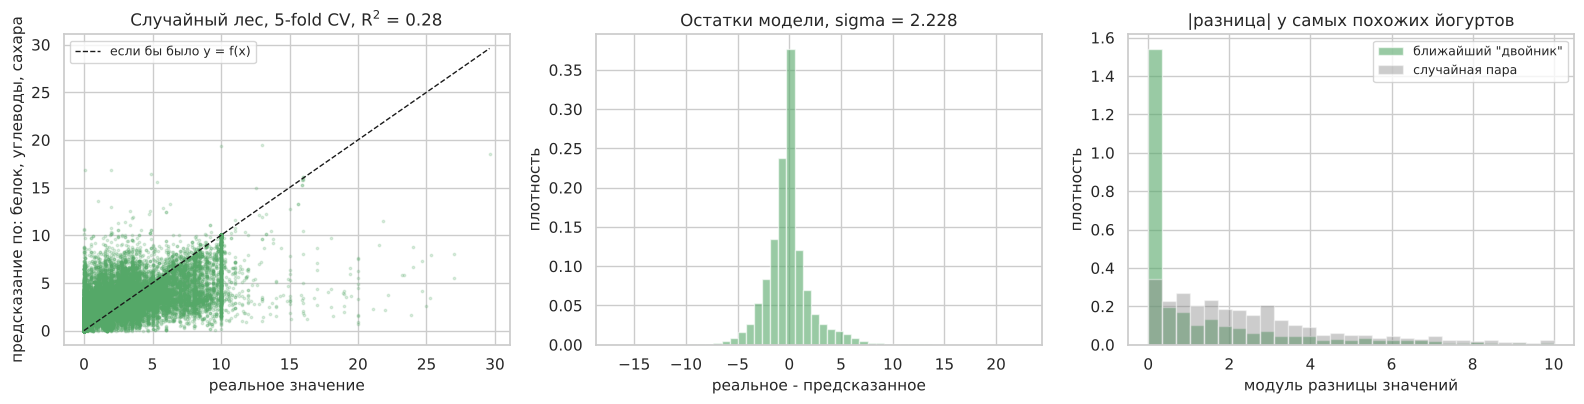

R2 (CV)                             0.278
sigma остатков                      2.228
sigma величины                      2.624
медиана |разн.| у двойников          0.21
медиана |разн.| у случайных пар      2.08
доля двойников с другим значением   0.592
dtype: float64

In [ ]:
features_f = ['proteins_100g', 'carbohydrates_100g', 'sugars_100g']
rand_f = lu.randomness_check(yog, 'fat_100g', features_f)
pd.Series(rand_f).round(3)

$R^2 = 0.28$, это наименьшее значение среди трех величин: жиры почти не связаны с остальными показателями. Остаточное стандартное отклонение 2.2 г почти равно общему (2.6 г), у 59% двойников жиры различаются. Жиры являются случайной величиной.

<a id="rv03-eda"></a>
### EDA & Distribution

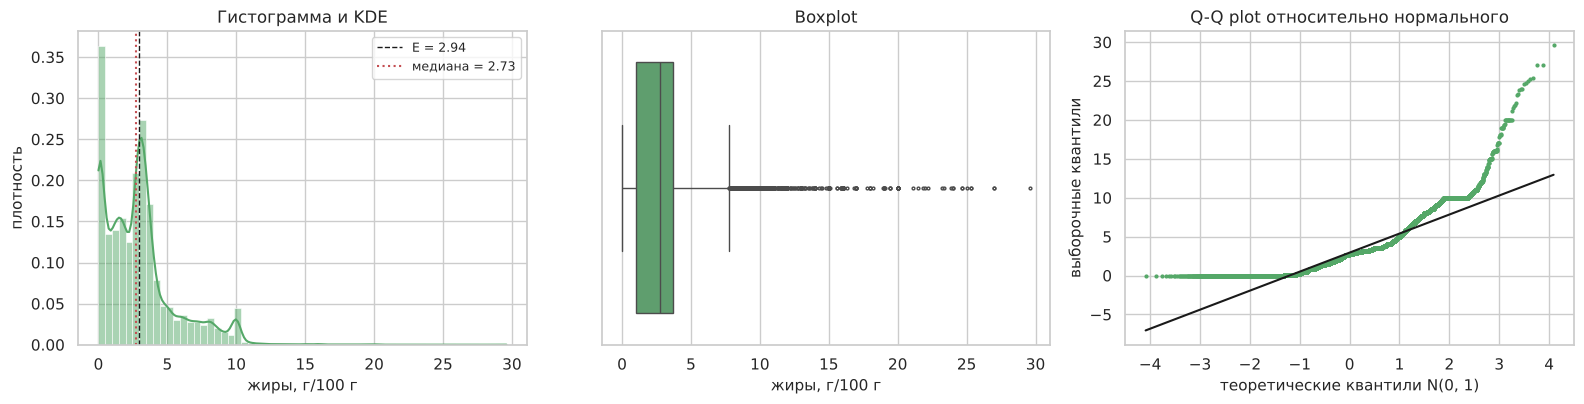

выбросов по правилу 1.5 IQR: 2282 (7.1%), границы [-3.05, 7.75]
самые частые значения: {0.0: 3047, 0.1: 1452, 3.0: 1377, 3.5: 896, 2.0: 885, 2.9: 802, 3.2: 772, 1.5: 751, 2.8: 740, 3.1: 730}
доля йогуртов с жирами <= 0 г: 0.095
доля йогуртов с жирами <= 0.1 г: 0.140
доля йогуртов с жирами <= 0.5 г: 0.198


In [ ]:
x = yog['fat_100g']
lu.eda_plots(x, 'fat_100g')
out, low, high = lu.outliers_iqr(x)
print(f'выбросов по правилу 1.5 IQR: {len(out)} ({len(out) / len(x) * 100:.1f}%), границы [{low:.2f}, {high:.2f}]')
print('самые частые значения:', x.round(2).value_counts().head(10).to_dict())
for t in [0, 0.1, 0.5]:
    print(f'доля йогуртов с жирами <= {t} г: {(x <= t).mean():.3f}')

Распределение жиров отличается от двух предыдущих. Во-первых, 14% йогуртов имеют жиры не больше 0.1 г (9.5% ровно 0), то есть в нуле находится заметная масса вероятности. Во-вторых, значения сосредоточены на стандартных уровнях жирности (3.0, 3.5, 2.0, 1.5 и т.д.), поэтому гистограмма состоит из отдельных пиков. Справа длинный хвост до 10 г и выше (жирные греческие и сливочные йогурты), асимметрия 1.6, эксцесс 4.9.

Для такой величины подходит смешанное распределение: часть вероятности сосредоточена в точке около нуля (обезжиренные йогурты), а остальные значения описываются непрерывным распределением. Границу обезжиренных йогуртов возьмем 0.5 г, этот порог обычно используется для маркировки «обезжиренный».

Функция распределения такой модели:

$$F(x) = p_0 + (1 - p_0) \cdot G(x), \quad x \ge 0.5$$

где $p_0 = P(X \le 0.5)$, а $G(x)$ функция распределения непрерывной части. Для непрерывной части подберем модель так же, как для белка.

p0 = P(жиры <= 0.5) = 0.198
для жиров больше 0.5 г: mu = 1.089, sigma = 0.646, медиана e^mu = 2.97 г


,число параметров,logL,AIC,BIC
нормальное,2,-5.993e+04,1.199e+05,1.199e+05
логнормальное,2,-5.338e+04,1.068e+05,1.068e+05
гамма,2,-5.389e+04,1.078e+05,1.078e+05


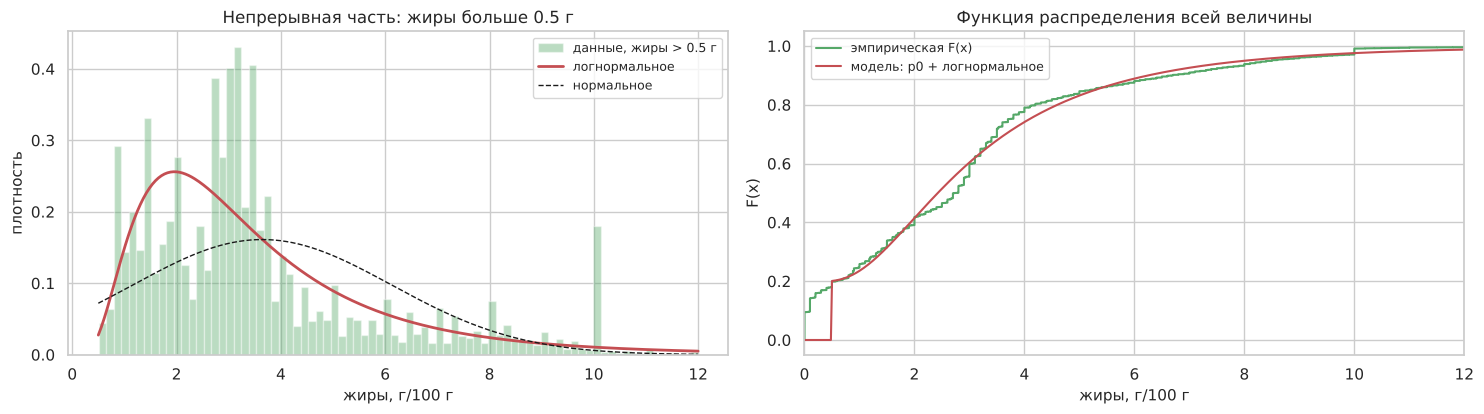

In [ ]:
p0 = (x <= 0.5).mean()
xf = x[x > 0.5]
s_f, _, scale_f = stats.lognorm.fit(xf, floc=0)
mu_f = np.log(scale_f)
print(f'p0 = P(жиры <= 0.5) = {p0:.3f}')
print(f'для жиров больше 0.5 г: mu = {mu_f:.3f}, sigma = {s_f:.3f}, медиана e^mu = {scale_f:.2f} г')
display(lu.fit_table(xf))
grid = np.linspace(0.5, 12, 400)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].hist(xf[xf <= 12], bins=80, density=True, color=lu.COLORS['fat_100g'], alpha=0.4, label='данные, жиры > 0.5 г')
axes[0].plot(grid, stats.lognorm.pdf(grid, s_f, scale=scale_f), 'r-', lw=2, label='логнормальное')
axes[0].plot(grid, stats.norm.pdf(grid, xf.mean(), xf.std()), 'k--', lw=1, label='нормальное')
axes[0].set_title('Непрерывная часть: жиры больше 0.5 г')
axes[0].set_xlabel(lu.LABELS['fat_100g'])
axes[0].set_ylabel('плотность')
axes[0].legend()
xs_all = np.sort(x.values)
axes[1].step(xs_all, np.arange(1, len(xs_all) + 1) / len(xs_all), where='post', color=lu.COLORS['fat_100g'], label='эмпирическая F(x)')
g2 = np.linspace(0, 12, 600)
model_cdf = np.where(g2 < 0.5, 0, p0 + (1 - p0) * stats.lognorm.cdf(np.maximum(g2, 0.5), s_f, scale=scale_f))
axes[1].plot(g2, model_cdf, 'r-', lw=1.5, label='модель: p0 + логнормальное')
axes[1].set_xlim(0, 12)
axes[1].set_title('Функция распределения всей величины')
axes[1].set_xlabel(lu.LABELS['fat_100g'])
axes[1].set_ylabel('F(x)')
axes[1].legend()
plt.tight_layout()
plt.show()

$p_0 = 0.198$: почти каждый пятый йогурт обезжиренный. Для непрерывной части лучшей моделью оказывается логнормальная ($\mu = 1.09$, $\sigma = 0.65$, медиана 2.97 г). Справа видно, что функция распределения модели в целом повторяет эмпирическую, но эмпирическая состоит из ступенек на стандартных уровнях жирности, которые непрерывная модель передать не может.

Логнормальная модель для жиров согласуется с тем же рассуждением, что и для белка: жиры в готовом продукте получаются умножением жирности основы на долю основы в продукте и на степень концентрирования.

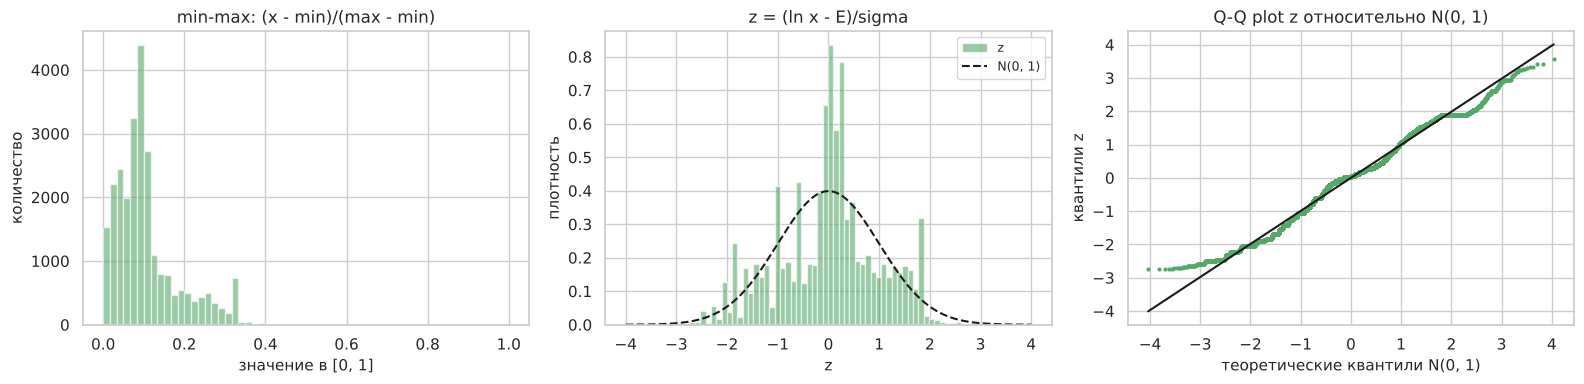

доля |z| < 1: 0.657 (у N(0, 1) 0.683)
доля |z| < 2: 0.965 (у N(0, 1) 0.954)
доля |z| < 3: 0.999 (у N(0, 1) 0.997)


In [ ]:
z_f = lu.normalize_plots(xf, 'fat_100g', log=True)
for k, ref in [(1, 0.683), (2, 0.954), (3, 0.997)]:
    print(f'доля |z| < {k}: {np.mean(np.abs(z_f) < k):.3f} (у N(0, 1) {ref})')

Для нормализации непрерывной части берем логарифм и стандартизируем. Получается распределение, близкое к $N(0, 1)$ по долям $|z| < 1, 2, 3$ (0.66, 0.97, 0.999), но немного более плоское в центре из-за отдельных пиков.

<a id="rv03-ind"></a>
### Independence & Estimations

Зависимость жиров от белка проверена в разделе [белок](#rv01-est): гипотеза о независимости отвергнута, связь отрицательная ($\rho = -0.20$). Здесь проверим состоятельность оценок.

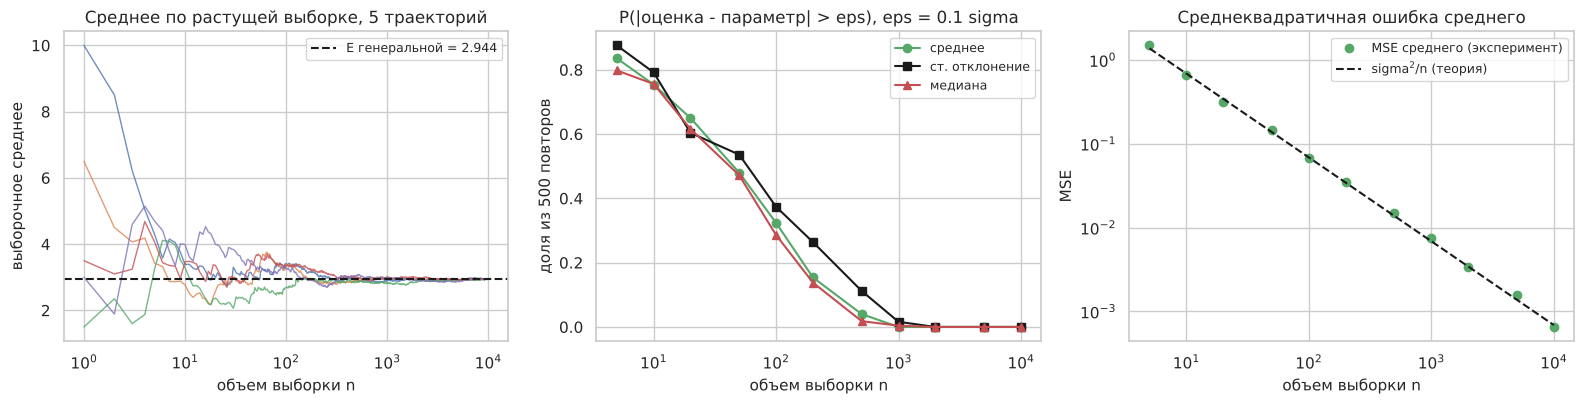

,n,P(|E* - E| > eps),P(|s - sigma| > eps),P(|Me* - Me| > eps),MSE(E*),sigma^2/n
0,5,0.836,0.876,0.798,1.496,1.377
1,10,0.754,0.792,0.756,0.6562,0.6887
2,20,0.65,0.604,0.616,0.3153,0.3444
3,50,0.48,0.536,0.472,0.1451,0.1378
4,100,0.324,0.374,0.286,0.06721,0.06887
5,200,0.154,0.264,0.138,0.03461,0.03444
6,500,0.04,0.112,0.018,0.01495,0.01377
7,1000,0,0.016,0.004,0.0076,0.00689
8,2000,0,0,0,0.00335,0.00344
9,5000,0,0,0,0.00159,0.00138


In [ ]:
cons_f = lu.consistency_plots(x, 'fat_100g')
cons_f.round(5)

Все три оценки состоятельны. Стандартное отклонение сходится медленнее остальных (при $n = 500$ ошибка больше $0.1\sigma$ в 11% случаев), потому что распределение имеет тяжелый правый хвост: редкие йогурты с жирностью 10 г и выше сильно влияют на оценку разброса.

<a id="rv03-samp"></a>
### Sampling

In [ ]:
table_f, s_with_f, s_without_f = lu.sample_compare(x)
table_f

,генеральная,с возвращением,без возвращения,первые 1000 строк
E,2.944,2.953,2.877,1.289
sigma,2.624,2.652,2.493,1.742
медиана,2.734,2.7,2.7,0.88
Q1,1,0.97,1,0
Q3,3.7,3.8,3.529,2
асимметрия,1.608,1.391,1.338,2.461
эксцесс,4.87,2.464,2.197,11.11
KS p-value (с генеральной),NaN,0.9,0.3886,0
разных йогуртов в выборке,3.215e+04,989,1000,1000


Обе случайные выборки соответствуют генеральной совокупности (KS p = 0.90 и 0.39), доля обезжиренных йогуртов в выборке 19.4% при 19.8% в совокупности. Первые 1000 строк дают среднее 1.29 г вместо 2.94 г: в начале файла собраны американские продукты, среди которых много обезжиренных.

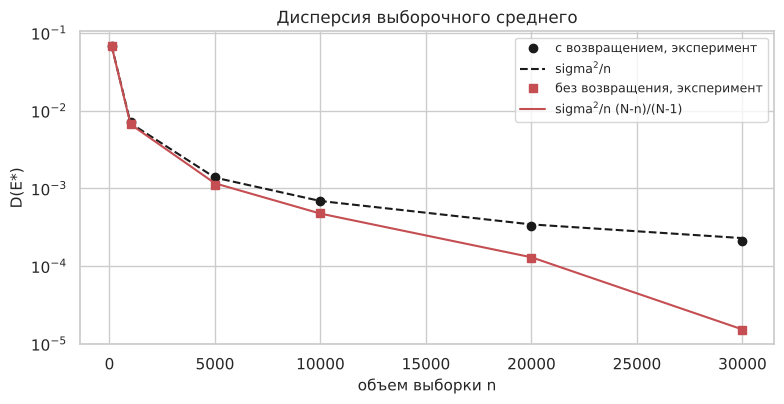

,n,n/N,"D(E*) с возвр., эксп.",sigma^2/n,"D(E*) без возвр., эксп.",sigma^2/n * (N-n)/(N-1)
0,100,0.00311,0.06829,0.06887,0.06716,0.06866
1,1000,0.0311,0.007138,0.006887,0.006706,0.006673
2,5000,0.1555,0.001386,0.001377,0.001098,0.001163
3,10000,0.311,0.0006985,0.0006887,0.0004881,0.0004745
4,20000,0.6221,0.0003313,0.0003444,0.0001293,0.0001302
5,30000,0.9331,0.0002111,0.0002296,1.502e-05,1.536e-05


In [ ]:
lu.fpc_experiment(x)

<a id="rv03-hyp"></a>
### Hypothesis

H5. $H_0$: непрерывная часть (жиры больше 0.5 г) имеет логнормальное распределение. Проверка по выборке $n = 1000$ критерием Шапиро-Уилка для логарифма.

In [ ]:
sf = s_without_f[s_without_f > 0.5]
print(f'выборка n = 1000, жиры > 0.5 г: n = {len(sf)}')
print(f'   ln(жиры), Шапиро-Уилк: p = {stats.shapiro(np.log(sf)).pvalue:.3g}')
print(f'   жиры, Шапиро-Уилк: p = {stats.shapiro(sf).pvalue:.3g}')
print(f'   доля жиров <= 0.5 г в выборке: {(s_without_f <= 0.5).mean():.3f} (в генеральной {p0:.3f})')

выборка n = 1000, жиры > 0.5 г: n = 806
   ln(жиры), Шапиро-Уилк: p = 6.39e-09
   жиры, Шапиро-Уилк: p = 5.75e-27
   доля жиров <= 0.5 г в выборке: 0.194 (в генеральной 0.198)


Гипотеза отвергается ($p \approx 6 \cdot 10^{-9}$). Логнормальное распределение лучшее из рассмотренных, но точно описать данные оно не может из-за стандартных уровней жирности: реальное распределение дискретно-непрерывное. Для практических целей (например, для генератора) модель «$p_0$ + логнормальное» дает правильные среднее и квантили, но не воспроизводит отдельные пики.

H6. $H_0$: доля обезжиренных йогуртов (жиры не больше 0.5 г) в США и во Франции одинакова. Используем z-критерий для разности двух долей:

$$z = \frac{\hat p_1 - \hat p_2}{\sqrt{\hat p(1 - \hat p)\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}$$

где $\hat p$ это общая доля по двум странам.

In [ ]:
usa = yog.loc[yog['usa'], 'fat_100g'] <= 0.5
fra = yog.loc[yog['france'], 'fat_100g'] <= 0.5
k1, n1, k2, n2 = usa.sum(), len(usa), fra.sum(), len(fra)
p1, p2 = k1 / n1, k2 / n2
pp = (k1 + k2) / (n1 + n2)
z = (p1 - p2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
print(f'США: {k1} из {n1}, доля {p1:.3f}')
print(f'Франция: {k2} из {n2}, доля {p2:.3f}')
print(f'z = {z:.1f}, p = {2 * stats.norm.sf(abs(z)):.3g}')
print(f"медиана белка в обезжиренных йогуртах США: {yog.loc[yog['usa'] & (yog['fat_100g'] <= 0.5), 'proteins_100g'].median():.2f}")

США: 1957 из 5955, доля 0.329
Франция: 871 из 8508, доля 0.102
z = 33.8, p = 6.5e-250
медиана белка в обезжиренных йогуртах США: 8.00


Гипотеза отвергается с большим запасом ($z = 33.8$): в США обезжиренным является каждый третий йогурт (32.9%), во Франции каждый десятый (10.2%). При этом медиана белка в американских обезжиренных йогуртах 8 г, то есть это в основном высокобелковые греческие продукты. Это согласуется с отрицательной связью белка и жиров, найденной выше.

<a id="rv03-res"></a>
### Resume

Содержание жиров является случайной величиной, слабее всего связанной с остальным составом ($R^2 = 0.28$). Распределение смешанное: 20% йогуртов обезжиренные, остальные приближенно описываются логнормальным распределением с медианой 3 г. Значения сосредоточены на стандартных уровнях жирности, поэтому непрерывные модели формально отвергаются. Доля обезжиренных йогуртов сильно различается по странам: в США она втрое больше, чем во Франции.

<a id="resume"></a>
## Lab resume

В работе исследованы три величины пищевой ценности йогуртов по данным Open Food Facts (32 151 продукт после очистки): содержание белка, сахаров и жиров.

Все три величины являются случайными. В отличие от энергетической ценности, которая вычисляется по составу почти точно, ни одну из них нельзя вычислить по другим показателям: по остальным составляющим белок объясняется на 43%, жиры на 28%. Сахара объясняются на 86%, так как они являются частью углеводов, но и у них остается заметный случайный разброс.

Ни одна величина не описывается одним стандартным распределением, и гипотезы о нормальности и логнормальности отвергаются для всех трех. Причина в том, что совокупность йогуртов неоднородна. Белок хорошо описывается смесью двух логнормальных распределений (обычные и концентрированные йогурты), сахара смесью двух нормальных (без добавленного сахара и сладкие), жиры смешанным распределением с массой в нуле (обезжиренные) и логнормальной непрерывной частью. Каждая компонента имеет понятный технологический смысл, и ее параметры правильно восстанавливаются по выборке из 1000 продуктов.

Между величинами обнаружены зависимости. Сахара почти полностью определяют углеводы ($\rho = 0.92$). Белок отрицательно связан с жирами ($\rho = -0.20$) и с сахарами ($\rho = -0.32$): высокобелковые йогурты обычно делают обезжиренными и несладкими. Доля таких продуктов зависит от страны: обезжиренных йогуртов в США 33%, во Франции 10%. Российские йогурты по белку значимо не отличаются от остальных в целом, но среди обычных (не греческих) йогуртов содержат немного меньше белка (медиана 3.25 г против 3.60 г). В натуральных йогуртах сахаров меньше, чем лактозы в молоке, что объясняется брожением.

Оценки среднего, стандартного отклонения и медианы состоятельны для всех величин, ошибка среднего убывает как $\sigma/\sqrt{n}$. Медиана сахаров сходится медленно, так как попадает в провал между пиками, а стандартное отклонение жиров из-за тяжелого хвоста. Случайная выборка объемом 1000 хорошо описывает генеральную совокупность по центру распределения, но асимметрию и эксцесс оценивает ненадежно. Выборка без возвращения точнее выборки с возвращением в $\frac{N-1}{N-n}$ раз по дисперсии среднего, что заметно при больших $n$. Порядок записей в исходном файле неслучаен, поэтому выборку нужно формировать только случайным отбором.

Для генератора случайных чисел во втором спринте удобнее всего использовать белок: его модель (смесь двух логнормальных) имеет простую структуру и ясный смысл.

<a id="metrics"></a>
### Итоговые метрики

In [ ]:
rows = {}
models = {
    'proteins_100g': f"{mix_p['w'][0]:.2f} LogN({mix_p['mu'][0]:.2f}; {mix_p['sd'][0]:.2f}) + {mix_p['w'][1]:.2f} LogN({mix_p['mu'][1]:.2f}; {mix_p['sd'][1]:.2f})",
    'sugars_100g': f"{mix_s['w'][0]:.2f} N({mix_s['mu'][0]:.2f}; {mix_s['sd'][0]:.2f}) + {mix_s['w'][1]:.2f} N({mix_s['mu'][1]:.2f}; {mix_s['sd'][1]:.2f})",
    'fat_100g': f"{p0:.2f} в точке ~0 + {1 - p0:.2f} LogN({mu_f:.2f}; {s_f:.2f})",
}
r2 = {'proteins_100g': rand_p, 'sugars_100g': rand_s, 'fat_100g': rand_f}
for col in ['proteins_100g', 'sugars_100g', 'fat_100g']:
    v = yog[col]
    rows[col] = {
        'n': len(v), 'E': v.mean(), 'sigma': v.std(), 'медиана': v.median(), 'IQR': v.quantile(0.75) - v.quantile(0.25),
        'асимметрия': stats.skew(v), 'эксцесс': stats.kurtosis(v),
        'R2 по другим нутриентам': r2[col]['R2 (CV)'],
        'модель': models[col],
    }
pd.DataFrame(rows).T

,n,E,sigma,медиана,IQR,асимметрия,эксцесс,R2 по другим нутриентам,модель
proteins_100g,32151,4.521,2.255,3.7,1.8,1.725,4.091,0.4265,0.85 LogN(1.27; 0.33) + 0.15 LogN(2.17; 0.18)
sugars_100g,32151,9.31,4.438,10,7.67,0.2464,1.22,0.8548,0.31 N(4.24; 1.20) + 0.69 N(11.77; 3.03)
fat_100g,32151,2.944,2.624,2.734,2.7,1.608,4.87,0.2779,0.20 в точке ~0 + 0.80 LogN(1.09; 0.65)


<a id="hyp-table"></a>
### Проверенные гипотезы

| # | $H_0$ | данные | критерий | p-value | вывод |
|---|-------|--------|----------|---------|-------|
| H1 | белок логнормальный (одна компонента) | выборка 1000 | Шапиро-Уилк для $\ln X$, BIC | $3 \cdot 10^{-22}$ | отвергается, лучше смесь двух |
| H2 | белок в России и в остальных странах распределен одинаково | 70 и 32 081 | Манн-Уитни | 0.073; без греческих 0.009 | в целом не отвергается, для обычных йогуртов отвергается |
| H3 | сахара нормальные (одна компонента) | выборка 1000 | Шапиро-Уилк, BIC | $10^{-17}$ | отвергается, лучше смесь двух |
| H4 | медиана сахаров в натуральных йогуртах 4.7 г | 2896 | Уилкоксон | $10^{-18}$ | отвергается, медиана 4.4 г |
| H5 | жиры больше 0.5 г логнормальные | выборка 1000 | Шапиро-Уилк для $\ln X$ | $6 \cdot 10^{-9}$ | отвергается, модель приближенная |
| H6 | доля обезжиренных в США и Франции одинакова | 5955 и 8508 | z-критерий для долей | $10^{-250}$ | отвергается, 33% и 10% |
| H7 | белок и жиры независимы | генеральная, выборка 1000 | Пирсон, Спирмен, $\chi^2$ | $< 10^{-4}$ | отвергается, $\rho = -0.20$ |
| H8 | сахара и углеводы независимы | генеральная | Пирсон, Спирмен | $\approx 0$ | отвергается, $\rho = 0.92$ |

<a id="marks"></a>
### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| 2.1 доказательство случайности | [белок](#rv01-desc), [сахара](#rv02-desc), [жиры](#rv03-desc) | | сравнение с формулой Этуотера, случайный лес, двойники, критерий серий |
| 2.2 независимость / зависимость | [белок и жиры](#rv01-est), [сахара и углеводы](#rv02-ind) | | Пирсон, Спирмен, $\chi^2$, V Крамера |
| 2.3 состоятельность оценок | [белок](#rv01-est), [сахара](#rv02-ind), [жиры](#rv03-ind) | | доля ошибок и MSE от n для среднего, s, медианы |
| 2.4 EDA, нормализация | [белок](#rv01-eda), [сахара](#rv02-eda), [жиры](#rv03-eda) | | очистка данных, min-max, z, логарифм + z |
| 2.5 выборка с возвращением и без | [белок](#rv01-samp), [сахара](#rv02-samp), [жиры](#rv03-samp) | | сравнение статистик, поправка $\frac{N-n}{N-1}$ |
| 2.6 мат. база распределения | [логнормальное и смесь](#rv01-math), [нормальное](#rv02-eda), [смешанное](#rv03-eda) | | плотности, параметры, связь с ЦПТ |
| 2.7 проверка гипотез | [таблица](#hyp-table) | | 8 гипотез |
| доп. приведение к стандартному нормальному | [белок](#rv01-norm) | | механика и мотивация |
| доп. за каждое распределение | [белок](#rv01-math), [сахара](#rv02-eda), [жиры](#rv03-eda) | | логнормальное, нормальное, смеси, смешанное |
| доп. табличное представление итоговых метрик | [метрики](#metrics) | | |
| доп. версионирование | история коммитов репозитория | | |